# Fit thermo - rev01

|                     |     |
| ------------------- | --- |
| **Status**          | Draft, 2026-11-04. Steps 1–3 only: the spectra of the reaction experiments, their concentrations in time, the spectra of the 10-day experiments |
| **Source**          | Y. Alcaraz Galván; NMR data from experiments (N. Gogoi, 2023), raw `.jdf` files |
| **Scope**           | The spectra of the five reaction folders and of the three folders `… AFTER 10 DAYS`, measured only, drawn as in `06_fitting_thermo_rev01` §6 |
| **Builds on**       | `06_fitting_thermo_rev01` (its figures and reading of the spectra, from `05_fitting_rev08_(M1_steps)` §2) |

### Dependences

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# The repository holds the code, the results and the data: run from notebooks/ or from the repository root
REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
CODE = REPO
if str(CODE) in sys.path:
    sys.path.remove(str(CODE))
sys.path.insert(0, str(CODE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.gridspec import GridSpec

import kinetics
from kinetics.data import calculate_molar_mass, load_lab_observables
from kinetics.data.lab_nmr import build_lab_nmr_inventory, calculate_area_shares, load_spectrum
from kinetics.data.observables import C_PHOSPHATE_WINDOWS_PPM, C_REGION_PPM, C_WINDOWS_PPM, P_WINDOWS_PPM, RT_MAX_C
from kinetics.fitting.reporting import P_REGION_PPM
from kinetics.fitting.residuals import SHARE_SPECIES
from kinetics.paths import lab_nmr_dir
from demo import fit_plots, style

assert Path(kinetics.__file__).parents[1] == CODE, f'kinetics was imported from {kinetics.__file__}, not from {CODE}'
style.apply_style()
pd.set_option('display.max_colwidth', None)

observables = load_lab_observables()
INVENTORY_ALL = build_lab_nmr_inventory(lab_nmr_dir())   # every .jdf of the raw data, copies included
print(f'Code: {CODE} · NMR data: {lab_nmr_dir()}')

Code: /home/yeray/projects/atom-to-reactor · NMR data: /home/yeray/data/nmr_raw_gogoi_2023


In [2]:
# The reading of the spectra of 06_fitting_thermo_rev01 (from 05_fitting_rev08 §2), measured only: the same windows, shares
# and figures, with no model drawn. Two changes: a spectrum is read with the windows of its tube (with or without phosphate),
# so a tube that is not in the observables (TMSOTMS + 2 % H2O, TMSOH + 2 % H2O) can be read too; and its time is the days
# since the first spectrum of its tube, from the acquisition times (no age before it)
SPECTRUM_VIEW = 'paper'
H1_REGION = (-0.35, 0.10)                     # ppm: the Si–CH3 region, where the phase of an FID is refined
# ²⁹Si, ppm as recorded (not referenced): HMDSO 7.8, TMSOH 14.2, TMS-EG 18.0, silyl on phosphate 21.6–23.0. Read by height
SI_WINDOWS = {'TMSOH': (13.0, 16.0), 'HMDSO': (6.5, 9.0), 'TMSOEG': (17.0, 20.0), 'P-silyl': (20.5, 25.0)}
SI_REGION = (-5.0, 35.0)
# ¹H, Si–CH3 region: one line per form of the silyl group (9 H each); TMSOH and HMDSO only 0.004–0.011 ppm apart, so one
# window takes all the free silyl
H1_WINDOWS = {'P-bound silyl': (-0.100, 0.060), 'free silyl': (-0.300, -0.150)}     # ppm (low, high)
H1_REFERENCES = {'TMSPA, fresh': (-0.041, 0), 'TMS-EG (paper)': (-0.215, 0), 'HMDSO (tube)': (-0.234, 1), 'TMSOH (paper)': (-0.245, 2)}   # ppm, label row
H1_SOLVENT = {'EC, CH₂ (s)': (4.224, 0), 'DEC, CH₂ (q)': (3.824, 0), 'H₂O (lock)': (3.288, 1), 'DMSO-d₅ (lock)': (2.462, 0),
              'DEC, CH₃ (t)': (0.944, 0), 'Si–CH₃': (-0.12, 0)}     # ppm, label row
# What the name or the title of a file says that its reading must keep in mind
FILE_NOTES = {'WW-NG-S1 TMSPa+H2O in EC-DEC_silicon-1-1.jdf': 'title WW-S12 (the ³¹P and ¹³C: WW-S1), recorded the evening before',
              '230515_5v%TMSPa+2v%TMSOH in EC_DEC_19F-1-2.jdf': 'named _19F, its header says ²⁹Si',
              'NG230525_5v% TMSPa+5v%TMSOH in EC_DEC_after 10d_Proton-1-1.jdf': 'titled 5v% TMSPa + 5v% TMSOH',
              'NG230525_5v% TMSPa+5v%TMSOH in EC_DEC_after 10d_inept_dec-1-1.jdf': 'titled 5v% TMSPa + 5v% TMSOH'}

# The tubes: 'first', the folders of its first spectra (the reaction experiment; the first spectrum of these is day 0 here);
# 'observables', its name in the observables (None: not a fitted tube). A file of a reaction folder is of the tube of the
# folder; a file of a folder '… AFTER 10 DAYS' is of the tube its title names (one folder holds two tubes)
TUBES = {'0.5 % H2O':         {'first': ['5% TMSPa + 0.5v% H2O in EC-DEC'], 'phosphate': True, 'observables': '0.5 % H2O'},
         '2 % H2O':           {'first': ['5% TMSPa + 2v% H2O in EC-DEC/Ramping Temperature',
                                         '5% TMSPa + 2v% H2O in EC-DEC/After Ramping Temperature'], 'phosphate': True, 'observables': '2 % H2O'},
         'TMSPa + TMSOH (A)': {'first': ['5v%TMSPa+2v%TMSOH in ECDEC'], 'phosphate': True, 'observables': 'TMSPa + TMSOH (A)'},
         'TMSOH + 2 % H2O':   {'first': ['5v% TMSOH+2v% H2O in ECDEC'], 'phosphate': False, 'observables': None},
         'TMSOTMS + 2 % H2O': {'first': ['5v%TMSOTMS+2v%H2O in ECDEC'], 'phosphate': False, 'observables': None},
         'TMSPa alone':       {'first': ['5v%TMSPa in EDEC'], 'phosphate': True, 'observables': 'TMSPa alone'}}
# Composition at mixing (M): the observables for a fitted tube; for the two others, the recipe (5 vol%) with the density of
# the liquid (g/mL, 25 °C: TMSOH 0.811 as in NB06 §6.0, HMDSO 0.764) and its molar mass
RECIPE_VOL_FRAC = {'TMSOH + 2 % H2O': {'TMSOH': 0.05}, 'TMSOTMS + 2 % H2O': {'HMDSO': 0.05}}
DENSITY_G_ML = {'TMSOH': 0.811, 'HMDSO': 0.764}


def mixing_c0(tube):
    name = TUBES[tube]['observables']
    if name:
        return observables['samples'][name]['c0_M']
    return {sp: f * 1000 * DENSITY_G_ML[sp] / calculate_molar_mass(sp) for sp, f in RECIPE_VOL_FRAC[tube].items()}


def abundant_concentration(rows, tube, nucleus):
    # The window with the largest share of one spectrum, and its concentration ± σ (mM). The windows of a nucleus count
    # together a conserved amount (³¹P: P atoms; ¹³C, ²⁹Si, ¹H: silyl groups), that of the mixing: Σ n × c0 over the
    # species of SHARE_SPECIES. A window of one species gives that species (share × total / n: HMDSO in molecules); a window
    # of several, their silyl groups (or P atoms). σ = √(σ_noise² + σ_baseline²) × total / n (²⁹Si, read by height: noise only)
    if rows['measured'].isna().all():               # windows not recorded
        return '', np.nan, np.nan
    members, c0 = SHARE_SPECIES[nucleus], mixing_c0(tube)
    total = sum(n * c0.get(sp, 0.0) for window in rows['window'] for sp, n in members[window].items())
    top = rows.loc[rows['measured'].idxmax()]
    species = members[top['window']]
    n, name = (next(iter(species.values())), next(iter(species))) if len(species) == 1 else (1, f"{top['window']} ({'P' if nucleus == '31P' else 'silyl groups'})")
    sigma = np.hypot(top['sigma_noise'], top['sigma_baseline'])
    return name, 1000 * top['measured'] * total / n, 1000 * sigma * total / n


TUBE_OF_FOLDER = {folder: tube for tube, record in TUBES.items() for folder in record['first']}
NUCLEUS_ORDER = ['31P', '13C', '29Si', '1H', '19F']      # the files table: one block per nucleus, in this order
LINE_REGIONS = {'31P': (-32.0, 6.0), '13C': (-3.0, 2.5), '1H': (-0.35, 0.10), '29Si': (0.0, 35.0), '19F': (-300.0, 100.0)}   # ppm: where S/N is read (NB06)


def tube_of(folder, title):
    # The tube of a file: that of its folder (reaction folders), else the one its title names
    if folder in TUBE_OF_FOLDER:
        return TUBE_OF_FOLDER[folder]
    if 'TMSOTMS' in title:
        return 'TMSOTMS + 2 % H2O'
    if 'TMSOH+2v%H2O' in title:
        return 'TMSOH + 2 % H2O'
    return 'TMSPa + TMSOH (A)' if 'TMSPa+' in title.replace(' ', '') else 'TMSPa alone'


def axis_offset(tube, nucleus):
    # The shift of the axis of a tube for one nucleus (observables: ¹³C of the tubes with phosphate); 0 elsewhere
    name = TUBES[tube]['observables']
    return observables['samples'][name].get('more_nuclei', {}).get(nucleus, {}).get('axis_offset_ppm', 0.0) if name else 0.0


def list_folder(folders):
    # One row per .jdf of one or more folders, in the order acquired: its tube, its days since the first spectrum of the
    # tube, its header and a note. A file whose data are those of another one (same md5) is a copy: drawn and listed once
    folders = [folders] if isinstance(folders, str) else folders
    files = INVENTORY_ALL[INVENTORY_ALL['folder'].isin(folders)].sort_values(['acquired_at', 'file']).reset_index(drop=True)
    files['tube'] = [tube_of(folder, title) for folder, title in zip(files['folder'], files['title'])]
    first = {tube: TUBES[tube].get('t0', INVENTORY_ALL.loc[INVENTORY_ALL['folder'].isin(TUBES[tube]['first']), 'acquired_at'].min()) for tube in files['tube'].unique()}
    files['days'] = [(at - first[tube]).total_seconds() / 86400 for at, tube in zip(files['acquired_at'], files['tube'])]
    original = files.drop_duplicates('data_md5').set_index('data_md5')['file']
    files['copy of'] = [original[md5] if copy else None for md5, copy in zip(files['data_md5'], files.duplicated('data_md5'))]
    notes = []
    for _, r in files.iterrows():
        note = [FILE_NOTES.get(r['file'], '')]
        if r['temperature_C'] > RT_MAX_C:
            note.append(f"{r['temperature_C']:.0f} °C")
        if r['nucleus'] == '31P' and (r['noe'] == 'TRUE' or r['relaxation_delay_s'] < 5):
            note.append(('NOE on, ' if r['noe'] == 'TRUE' else '') + f"d1 {r['relaxation_delay_s']:g} s")
        if r['nucleus'] == '29Si':
            note.append('INEPT' if 'inept' in r['experiment'] else 'NOE on')
        if isinstance(r['copy of'], str):
            note.append(f"copy of {r['copy of']}")
        notes.append(', '.join(n for n in note if n))
    files['note'] = notes
    return files


def load_phased(path, window=None):
    return load_spectrum(path, window_ppm=window)


def signal_to_noise(path, nucleus, offset=0.0):
    # S/N = height of the tallest line over the baseline reference (median of the region) / (2 σ_noise), in the region where
    # the lines of the species are (LINE_REGIONS, moved by the axis offset of the tube). σ_noise: the spread (MAD) of the
    # differences between neighbouring points / √2, which a sloping baseline does not raise (NB06 peak_to_noise)
    low, high = LINE_REGIONS[nucleus]
    ppm, intensity = load_phased(path, (low + offset, high + offset) if nucleus != '1H' or h1_phase_window(path) else None)
    y = intensity[(ppm >= low + offset) & (ppm <= high + offset)]
    if y.size < 3:                                    # the region was not recorded
        return np.nan
    step = np.diff(y)
    sigma = 1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)
    return float((y.max() - np.median(y)) / (2 * sigma))


def h1_phase_window(path):
    # The ¹H region whose phase is refined: that of Si–CH3 for an FID; none for a spectrum processed on the spectrometer
    return H1_REGION if INVENTORY_ALL.set_index('path').loc[path, 'data_kind'] == 'FID' else None


def calculate_height_shares(ppm, intensity, windows_ppm, *, region_ppm, pad_ppm=0.5):
    # ²⁹Si: the share of the summed height (its lines are one or two points wide on a rolling baseline). Each height is the
    # tallest point of the window over the median of two pads beside it; an empty window reads the top of its noise, about 4 σ
    inside = (ppm >= region_ppm[0]) & (ppm <= region_ppm[1])
    x, y = ppm[inside], intensity[inside]
    step = np.diff(y)
    noise = 1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)
    heights = {}
    for name, (low, high) in windows_ppm.items():
        pads = ((x >= low - pad_ppm) & (x < low)) | ((x > high) & (x <= high + pad_ppm))
        heights[name] = float(y[(x >= low) & (x <= high)].max() - np.median(y[pads]))
    total = sum(heights.values())
    shares = pd.DataFrame({'share': {name: h / total for name, h in heights.items()}, 'height': heights})
    shares['sigma'] = [noise * np.sqrt((1.0 - s) ** 2 + s ** 2 * (len(heights) - 1)) / total for s in shares['share']]
    return shares


def reading_of(nucleus, tube):
    # Windows, region and options of the shares of a spectrum, as in NB06; a tube without phosphate has no window for the
    # silyl on phosphate
    offset, phosphate = axis_offset(tube, nucleus), TUBES[tube]['phosphate']
    if nucleus == '31P':
        return P_WINDOWS_PPM, P_REGION_PPM, {}
    if nucleus == '13C':
        windows = C_PHOSPHATE_WINDOWS_PPM if phosphate else C_WINDOWS_PPM
        return ({window: (low + offset, high + offset) for window, (low, high) in windows.items()},
                (C_REGION_PPM[0] + offset, C_REGION_PPM[1] + offset), {})
    if nucleus == '29Si':
        return {window: limits for window, limits in SI_WINDOWS.items() if window != 'P-silyl' or phosphate}, SI_REGION, {}
    if nucleus == '1H':
        return ({window: limits for window, limits in H1_WINDOWS.items() if window != 'P-bound silyl' or phosphate},
                (-1.0, 0.6), {'baseline_pad_ppm': 0.1, 'exclusion_pad_ppm': 0.05})
    return None


def read_spectrum(path, nucleus, tube):
    # Shares of one spectrum and, but for ¹H, the spectrum as NB06 draws it: cut to the region, a cubic baseline removed
    # outside the windows, divided by the summed area of the windows
    windows, region, options = reading_of(nucleus, tube)
    if nucleus == '1H' and load_phased(path)[0].min() > min(high for _, high in windows.values()):     # Si–CH3 not recorded
        return pd.DataFrame({'share': np.nan, 'sigma': np.nan, 'sigma_noise': np.nan, 'sigma_baseline': np.nan}, index=list(windows)), None
    ppm, intensity = load_phased(path, h1_phase_window(path) if nucleus == '1H' else region)
    if nucleus == '29Si':
        shares = calculate_height_shares(ppm, intensity, windows, region_ppm=region)
    else:
        shares = calculate_area_shares(ppm, intensity, windows, region_ppm=region, **options)
    if nucleus == '1H':
        return shares, None
    inside = (ppm >= region[0]) & (ppm <= region[1])
    x, y = ppm[inside], intensity[inside]
    free = np.ones(len(x), dtype=bool)
    for low, high in windows.values():
        free &= ~((x >= low - 0.3) & (x <= high + 0.3))
    y = y - np.polyval(np.polyfit(x[free], y[free], 3), x)
    area = sum(float(y[(x >= low) & (x <= high)].sum() * abs(x[1] - x[0])) for low, high in windows.values())
    if nucleus == '29Si':                             # read by height: the area its lines would have at the width of the tallest one
        top = int(np.argmax(y))
        area = float(shares['height'].sum()) * 1.0645 * abs(x[1] - x[0]) * max(1, int(np.sum(y[max(0, top - 20):top + 21] > 0.5 * y[top])))
    return shares, {'ppm': x, 'intensity': y / area, 'area': area, 'windows_ppm': dict(windows), 'axis_offset_ppm': axis_offset(tube, nucleus)}


def label_row(row):
    # The label of a spectrum in the figures: days since the first spectrum of its tube, and what sets it apart
    when = f"{1440 * row['days']:.1f} min" if 't0' in TUBES[row['tube']] else f"{row['days']:.1f} d"     # a tube with a time zero: minutes since it
    return when + (f", {row['note']}" if row['note'] else '')      # the note holds the temperature of a hot spectrum


def add_h1_rows(fig, axes, h1, title=None):
    # One row per ¹H spectrum: the whole spectrum, then its Si–CH3 region with the measured shares, as in NB06 (no simulated
    # line). Under the axes of fig when fig is given; otherwise a figure of its own
    files = list(h1.drop_duplicates('path').sort_values('spectrum')['path'])      # in the order acquired
    if fig is None:
        fig = plt.figure(figsize=(9.6, 0.9 + 2.6 * len(files)), layout='constrained')
        grid = GridSpec(len(files), 1, figure=fig)
        rows = [grid[k] for k in range(len(files))]
        fig.suptitle(title, x=0.01, ha='left', fontsize=11)
    else:
        width, height = fig.get_size_inches()
        fig.set_size_inches(width, height + 2.6 * len(files))
        grid = GridSpec(1 + len(files), 1, figure=fig, height_ratios=[height - 0.9] + [2.6] * len(files))
        for k, ax in enumerate(axes.flat):
            ax.set_subplotspec(grid[0].subgridspec(len(axes.flat), 1)[k])
        rows = [grid[1 + k] for k in range(len(files))]
    for k, (file, spec) in enumerate(zip(files, rows)):
        seen = h1[h1['path'] == file].set_index('window')
        whole, zoom = (fig.add_subplot(s) for s in spec.subgridspec(1, 2, width_ratios=[1.6, 1]))
        ppm, intensity = load_phased(file)          # the whole spectrum with its own phase; the Si–CH3 region with the phase of that region
        y = intensity / intensity.max()
        region = (ppm <= 4.7) & (ppm >= -0.45)
        whole.plot(ppm[region], y[region], color=style.SERIES[7], lw=0.7)
        for name, (position, row) in H1_SOLVENT.items():
            near = np.abs(ppm - position) < 0.05
            if not near.any():                        # outside the recorded range
                continue
            whole.text(position, y[near].max() + 0.04 + 0.12 * row, name, ha='center', va='bottom', fontsize=7.5, color=fit_plots.INK)
        whole.axvspan(-0.30, 0.06, color=fit_plots.GRID, alpha=0.45, lw=0)
        whole.set_xlim(4.7, -0.45); whole.set_ylim(-0.05, 1.25); whole.set_yticks([]); whole.grid(False)
        whole.set_xlabel('δ(¹H) (ppm)')
        whole.set_ylabel(f"{seen.iloc[0]['tube']}\n{label_row(seen.iloc[0])}, ¹H", rotation=0, ha='right', va='center', fontsize=8.5, color=fit_plots.INK)
        if seen['measured'].isna().all():            # Si–CH3 region not recorded: the zoom left empty
            zoom.set_xlim(0.10, -0.35); zoom.set_yticks([]); zoom.grid(False)
            zoom.text(0.5, 0.5, 'Si–CH₃ region not recorded', transform=zoom.transAxes, ha='center', va='center', fontsize=8.5, color=fit_plots.INK_MUTED)
            zoom.set_xlabel('δ(¹H) (ppm), Si–CH₃')
            continue
        ppm, intensity = load_phased(file, h1_phase_window(file))
        region = (ppm <= 0.10) & (ppm >= -0.35)
        y = intensity[region] / intensity[region].max()
        for name, (low, high) in H1_WINDOWS.items():
            if name not in seen.index:                # the window of the silyl on phosphate, in a tube without phosphate
                continue
            zoom.axvspan(low, high, color=fit_plots.GRID, alpha=0.45, lw=0)
            zoom.text(0.5 * (low + high), 1.5, name, ha='center', va='bottom', fontsize=8.5, color=fit_plots.INK)
            zoom.text(0.5 * (low + high), 1.3, f"{seen.loc[name, 'measured']:.2f}", ha='center', va='center', fontsize=7.5, color=fit_plots.INK_SOFT)
        zoom.plot(ppm[region], y, color=style.SERIES[7], lw=0.7, zorder=3)
        for name, (position, row) in H1_REFERENCES.items():
            zoom.axvline(position, ymax=0.75, color=fit_plots.INK_SOFT, ls=':', lw=0.8)
            zoom.text(position, -0.1 - 0.15 * row, f'{name} {position:+.3f}', ha='center', va='top', fontsize=6.5, color=fit_plots.INK_SOFT)
        zoom.set_xlim(0.10, -0.35); zoom.set_ylim(-0.55, 1.75); zoom.set_yticks([]); zoom.grid(False)
        zoom.set_xlabel('δ(¹H) (ppm), Si–CH₃')
        if k == 0:
            whole.text(0.55, 0.95, 'Spectrum: lab NMR data.\nLines identified with Gogoi et al., Fig. 5b\n(HMDSO from the HMDSO + H₂O tube).',
                       transform=whole.transAxes, ha='center', va='top', fontsize=7.5, color=fit_plots.INK_SOFT)
    return fig


def tabulate_folder(files):
    # Every spectrum of a folder read (copies once), one row per window, in the columns plot_spectra_comparison reads
    # ('predicted' NaN: nothing is simulated here); and the spectra read for the figures (¹H: drawn by add_h1_rows)
    rows, spectra = [], {}
    for number, (_, r) in enumerate(files[files['copy of'].isna()].iterrows()):
        if reading_of(r['nucleus'], r['tube']) is None:
            continue
        measured, spectrum = read_spectrum(r['path'], r['nucleus'], r['tube'])
        if spectrum is not None:
            spectra[(r['tube'], r['nucleus'], number)] = spectrum
        rows += [{'sample': r['tube'], 'tube': r['tube'], 'nucleus': r['nucleus'], 'spectrum': number, 't_h': 24 * r['days'],
                  'days': r['days'], 'T_C': r['temperature_C'], 'window': window, 'measured': m['share'], 'sigma_nmr': m['sigma'],
                  'sigma_noise': m.get('sigma_noise', m['sigma']), 'sigma_baseline': m.get('sigma_baseline', 0.0),
                  'predicted': np.nan, 'note': r['note'], 'file': r['file'], 'path': r['path']} for window, m in measured.iterrows()]
    return pd.DataFrame(rows), spectra


def tabulate_files(files, shares):
    # The files table: one block per nucleus (NUCLEUS_ORDER), each in the order acquired; copies once. The species with the
    # largest share and its concentration ± σ (abundant_concentration)
    table = files[files['copy of'].isna()].copy()
    read = {path: abundant_concentration(rows, rows['tube'].iloc[0], rows['nucleus'].iloc[0]) for path, rows in shares.groupby('path')}
    table['species'] = [read[path][0] if path in read else '' for path in table['path']]
    table['conc. (mM)'] = [read[path][1] if path in read else np.nan for path in table['path']]
    table['σ (mM)'] = [read[path][2] if path in read else np.nan for path in table['path']]
    table['σ (%)'] = 100 * table['σ (mM)'] / table['conc. (mM)']
    table['S/N'] = [signal_to_noise(r['path'], r['nucleus'], axis_offset(r['tube'], r['nucleus'])) for _, r in table.iterrows()]
    table['time per scan (s)'] = 60 * table['duration_min'] / table['scans']
    table['order'] = table['nucleus'].map({n: k for k, n in enumerate(NUCLEUS_ORDER)})
    table = table.sort_values(['order', 'acquired_at'], kind='stable')
    return table.rename(columns={'acquired_at': 'acquired', 'scans': 'scans', 'relaxation_delay_s': 'delay d1 (s)', 'temperature_C': 'T (°C)'})[
        ['nucleus', 'acquired', 'species', 'conc. (mM)', 'σ (mM)', 'σ (%)', 'S/N', 'scans', 'time per scan (s)', 'delay d1 (s)', 'T (°C)']]


def show_folder(folders, when=''):
    # One or more folders, nucleus by nucleus (NUCLEUS_ORDER), each under its letter: the figure of its spectra (every tube
    # of the folder, in the order acquired; ¹H as the rows of NB06), then its tables: the files, and the measured shares
    files = list_folder(folders)
    shares, spectra = tabulate_folder(files)
    table = tabulate_files(files, shares)
    for letter, nucleus in zip('ABCDEFG', [n for n in NUCLEUS_ORDER if n in set(table['nucleus'])]):
        label = fit_plots.NUCLEUS_LABELS.get(nucleus, nucleus)
        display(Markdown(f'#### {letter}. {label}'))
        mine = shares[shares['nucleus'] == nucleus]
        title = f"{', '.join(mine['tube'].unique())}, {label}: measured{when}"
        if nucleus == '1H' and len(mine):
            fig = add_h1_rows(None, None, mine, title=title)
            display(fig)
            plt.close(fig)
        elif len(mine):
            seen = mine.drop_duplicates('spectrum').sort_values('spectrum')
            axes = fit_plots.plot_spectra_comparison(spectra, mine, nucleus=nucleus,
                                                     rows=[(r['tube'], int(r['spectrum']), label_row(r)) for _, r in seen.iterrows()],
                                                     fit_label='Simulated: none (measured only)', title=title, view=SPECTRUM_VIEW)
            display(axes.flat[0].figure)
            plt.close(axes.flat[0].figure)
        display(table[table['nucleus'] == nucleus].style.hide(axis='index')
                .format({'conc. (mM)': '{:.1f}', 'σ (mM)': '{:.1f}', 'σ (%)': '{:.1f}', 'S/N': '{:.0f}', 'time per scan (s)': '{:.2f}', 'delay d1 (s)': '{:g}', 'T (°C)': '{:.1f}'}))
        if len(mine):
            display(mine.assign(share=mine['measured'], σ=mine['sigma_nmr'])
                    .pivot_table(index=['tube', 'days'], columns='window', values=['share', 'σ'], sort=False)
                    .style.format('{:.3f}', na_rep='').format_index('{:.2f}', level=1))

## 1. NMR original data

---
### 1.1 Reaction experiments

#### 1.1.1 `5% TMSPa + 0.5v% H2O`

`0.5 % H2O`. The ²⁹Si (title WW-S12) was recorded the evening before the ³¹P and ¹³C (WW-S1): it is the first spectrum of the tube, day 0.

#### A. ³¹P

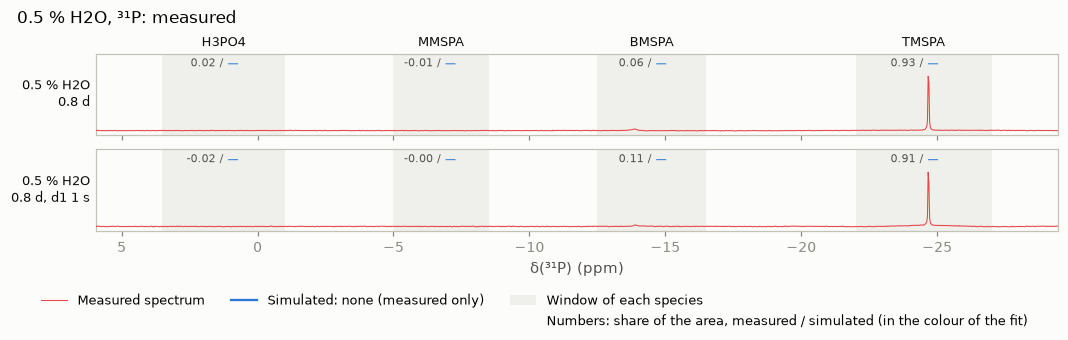

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2022-04-22 12:58:50,TMSPA,139.0,2.9,2.1,233,16,5.69,5,22.3
31P,2022-04-22 13:01:19,TMSPA,135.9,7.2,5.3,163,16,1.56,1,22.3


#### B. ¹³C

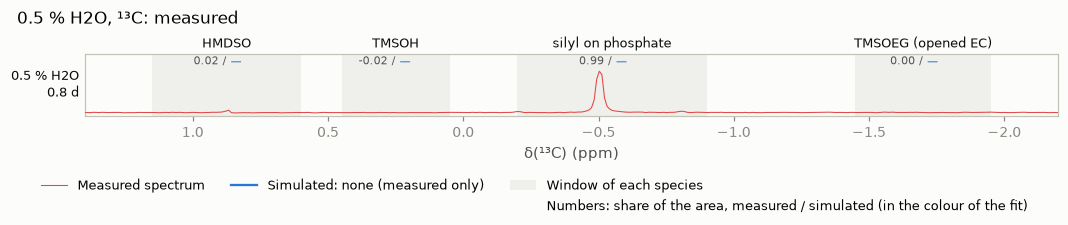

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
13C,2022-04-22 13:03:20,P-silyl (silyl groups),445.9,5.7,1.3,234,256,3.10,2,22.3


#### C. ²⁹Si

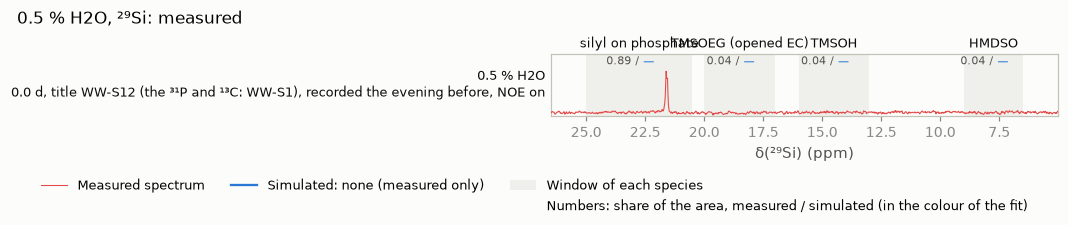

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2022-04-21 18:07:01,P-silyl (silyl groups),398.2,7.2,1.8,44,6000,5.66,5,21.8


In [3]:
show_folder('5% TMSPa + 0.5v% H2O in EC-DEC')

#### 1.1.2 `5% TMSPa + 2v% H2O`

`2 % H2O`: its two folders together, `Ramping Temperature` (spectra at 30–80 °C) and `After Ramping Temperature` (back at room temperature after each heating).

#### A. ³¹P

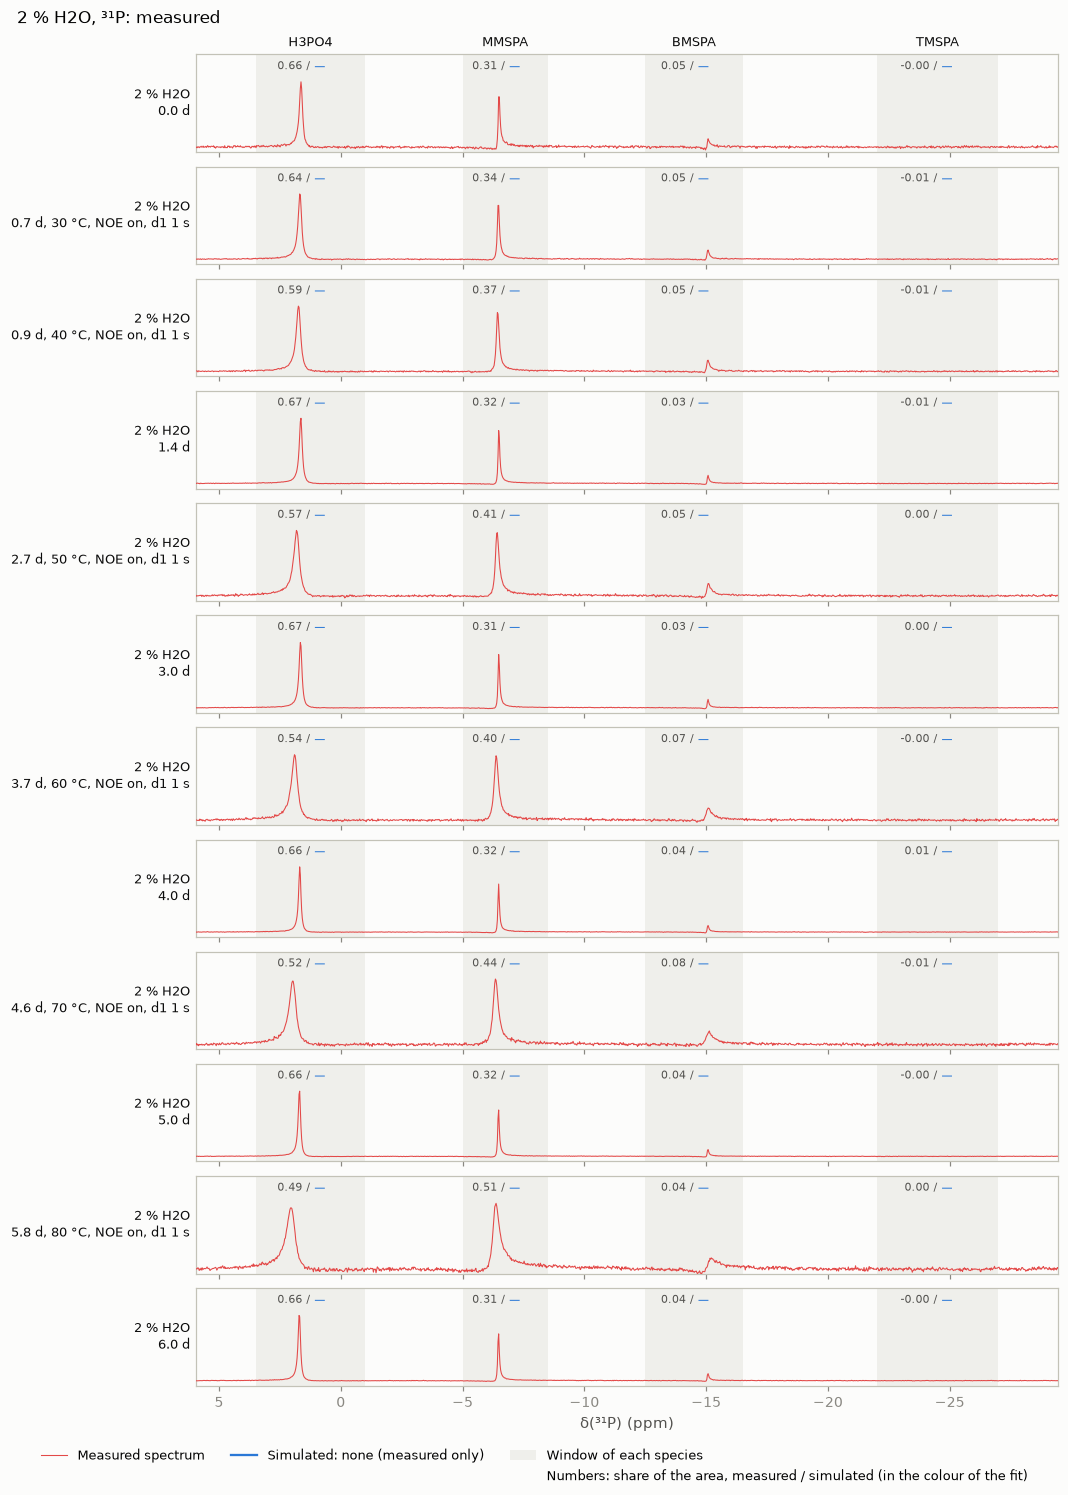

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2022-06-22 18:09:08,H3PO4,99.3,1.8,1.8,55,16,5.69,5,22.5
31P,2022-06-23 10:41:15,H3PO4,95.4,0.7,0.7,127,256,1.52,1,30.0
31P,2022-06-23 15:33:20,H3PO4,88.8,1.1,1.3,86,256,1.54,1,40.0
31P,2022-06-24 03:09:41,H3PO4,99.6,1.0,1.1,229,256,5.26,5,22.3
31P,2022-06-25 11:33:27,H3PO4,85.3,2.7,3.2,63,256,1.52,1,50.0
31P,2022-06-25 18:09:13,H3PO4,99.6,1.6,1.6,242,256,5.25,5,22.4
31P,2022-06-26 09:47:56,H3PO4,80.9,1.2,1.5,54,256,1.53,1,60.0
31P,2022-06-26 18:09:29,H3PO4,98.1,2.1,2.1,275,256,5.25,5,22.5
31P,2022-06-27 08:08:41,H3PO4,77.1,4.8,6.3,42,256,1.53,1,70.0
31P,2022-06-27 18:09:35,H3PO4,98.3,0.9,1.0,286,256,5.25,5,22.8


#### B. ¹³C

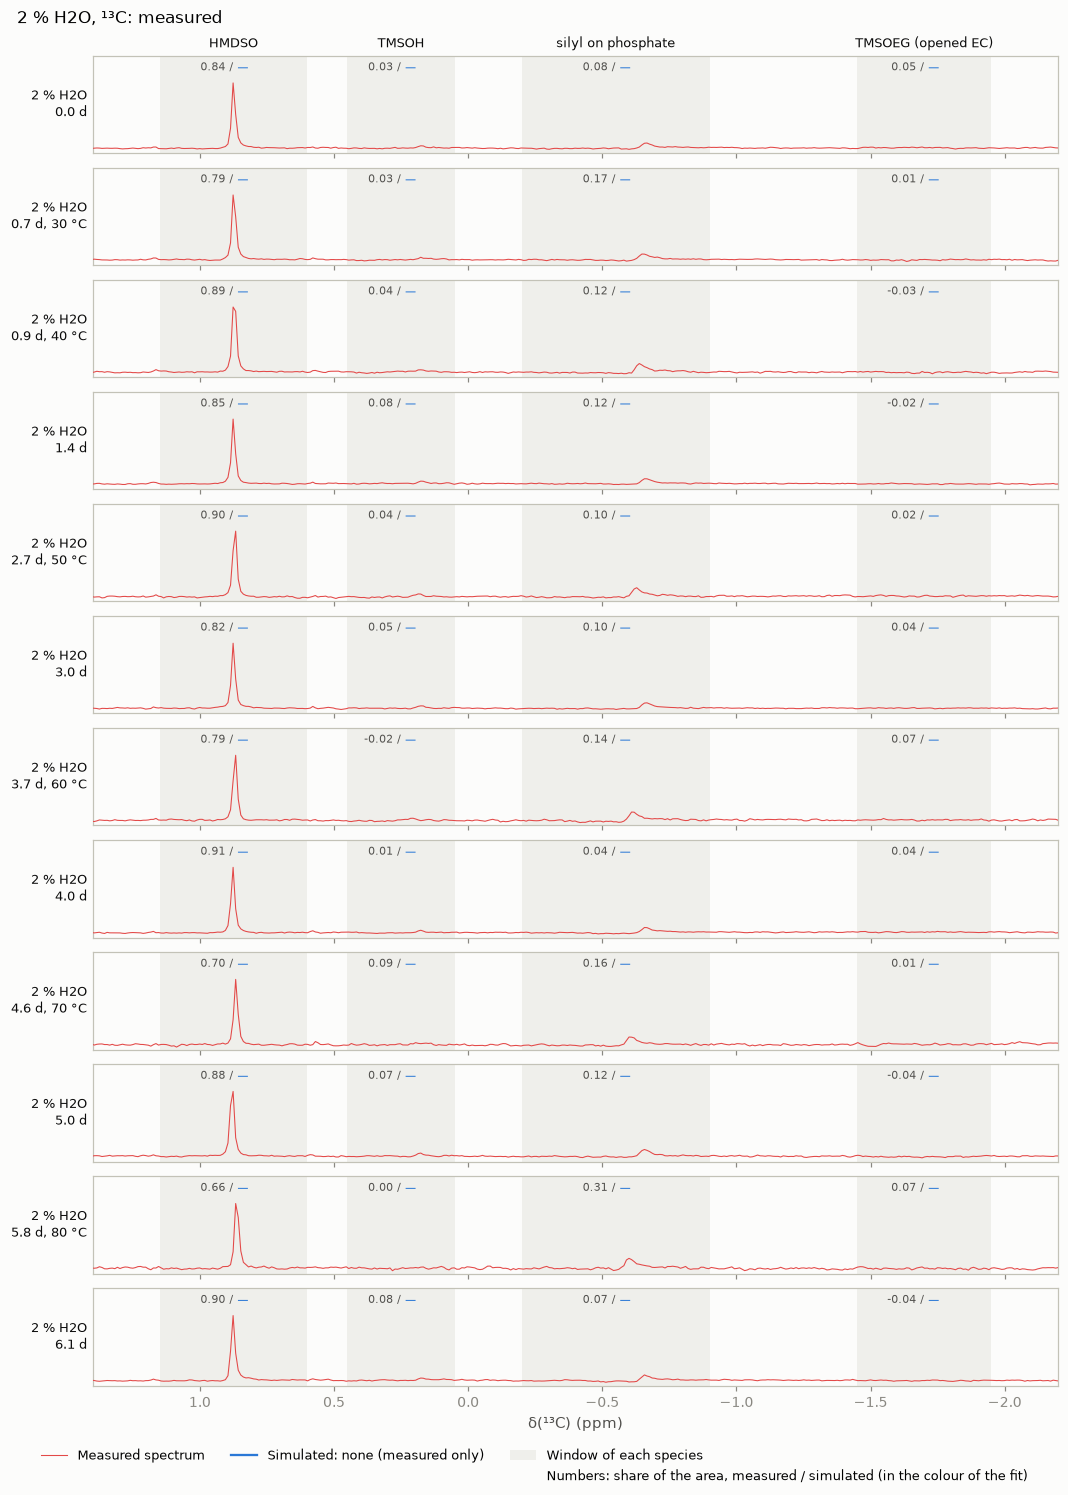

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
13C,2022-06-22 18:12:20,HMDSO,189.1,5.7,3.0,127,50,3.30,2,22.4
13C,2022-06-23 10:35:55,HMDSO,177.5,23.0,13.0,113,64,3.27,2,30.0
13C,2022-06-23 15:28:03,HMDSO,199.4,15.6,7.8,89,64,3.25,2,40.0
13C,2022-06-24 03:33:44,HMDSO,190.1,34.7,18.2,127,64,3.25,2,22.3
13C,2022-06-25 11:28:04,HMDSO,201.1,37.8,18.8,82,64,3.25,2,50.0
13C,2022-06-25 18:33:17,HMDSO,184.2,5.0,2.7,126,64,3.25,2,22.4
13C,2022-06-26 09:42:15,HMDSO,177.3,27.6,15.6,88,64,3.25,2,60.0
13C,2022-06-26 18:34:36,HMDSO,203.4,19.2,9.4,130,64,3.25,2,22.5
13C,2022-06-27 08:03:17,HMDSO,157.6,36.8,23.4,67,64,3.25,2,70.0
13C,2022-06-27 18:33:35,HMDSO,196.2,19.9,10.1,99,64,3.25,2,22.8


#### C. ²⁹Si

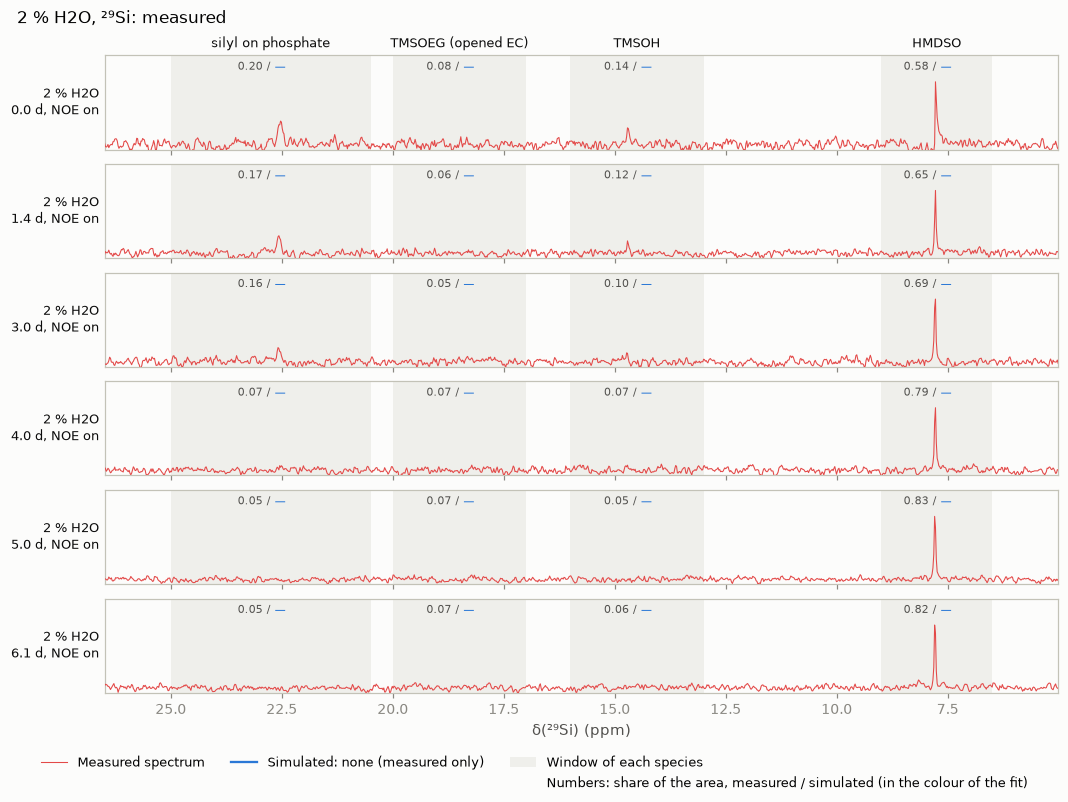

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2022-06-22 18:16:40,HMDSO,129.0,4.0,3.1,18,6000,5.66,5,22.3
29Si,2022-06-24 03:38:40,HMDSO,145.1,3.6,2.5,24,6000,5.66,5,22.3
29Si,2022-06-25 18:38:15,HMDSO,155.0,4.3,2.8,22,6000,5.66,5,22.3
29Si,2022-06-26 18:39:30,HMDSO,177.1,5.1,2.9,24,6000,5.66,5,22.5
29Si,2022-06-27 18:38:34,HMDSO,185.4,4.1,2.2,32,6000,5.66,5,22.5
29Si,2022-06-28 19:39:09,HMDSO,184.5,4.8,2.6,28,6000,5.66,5,22.6


#### D. ¹H

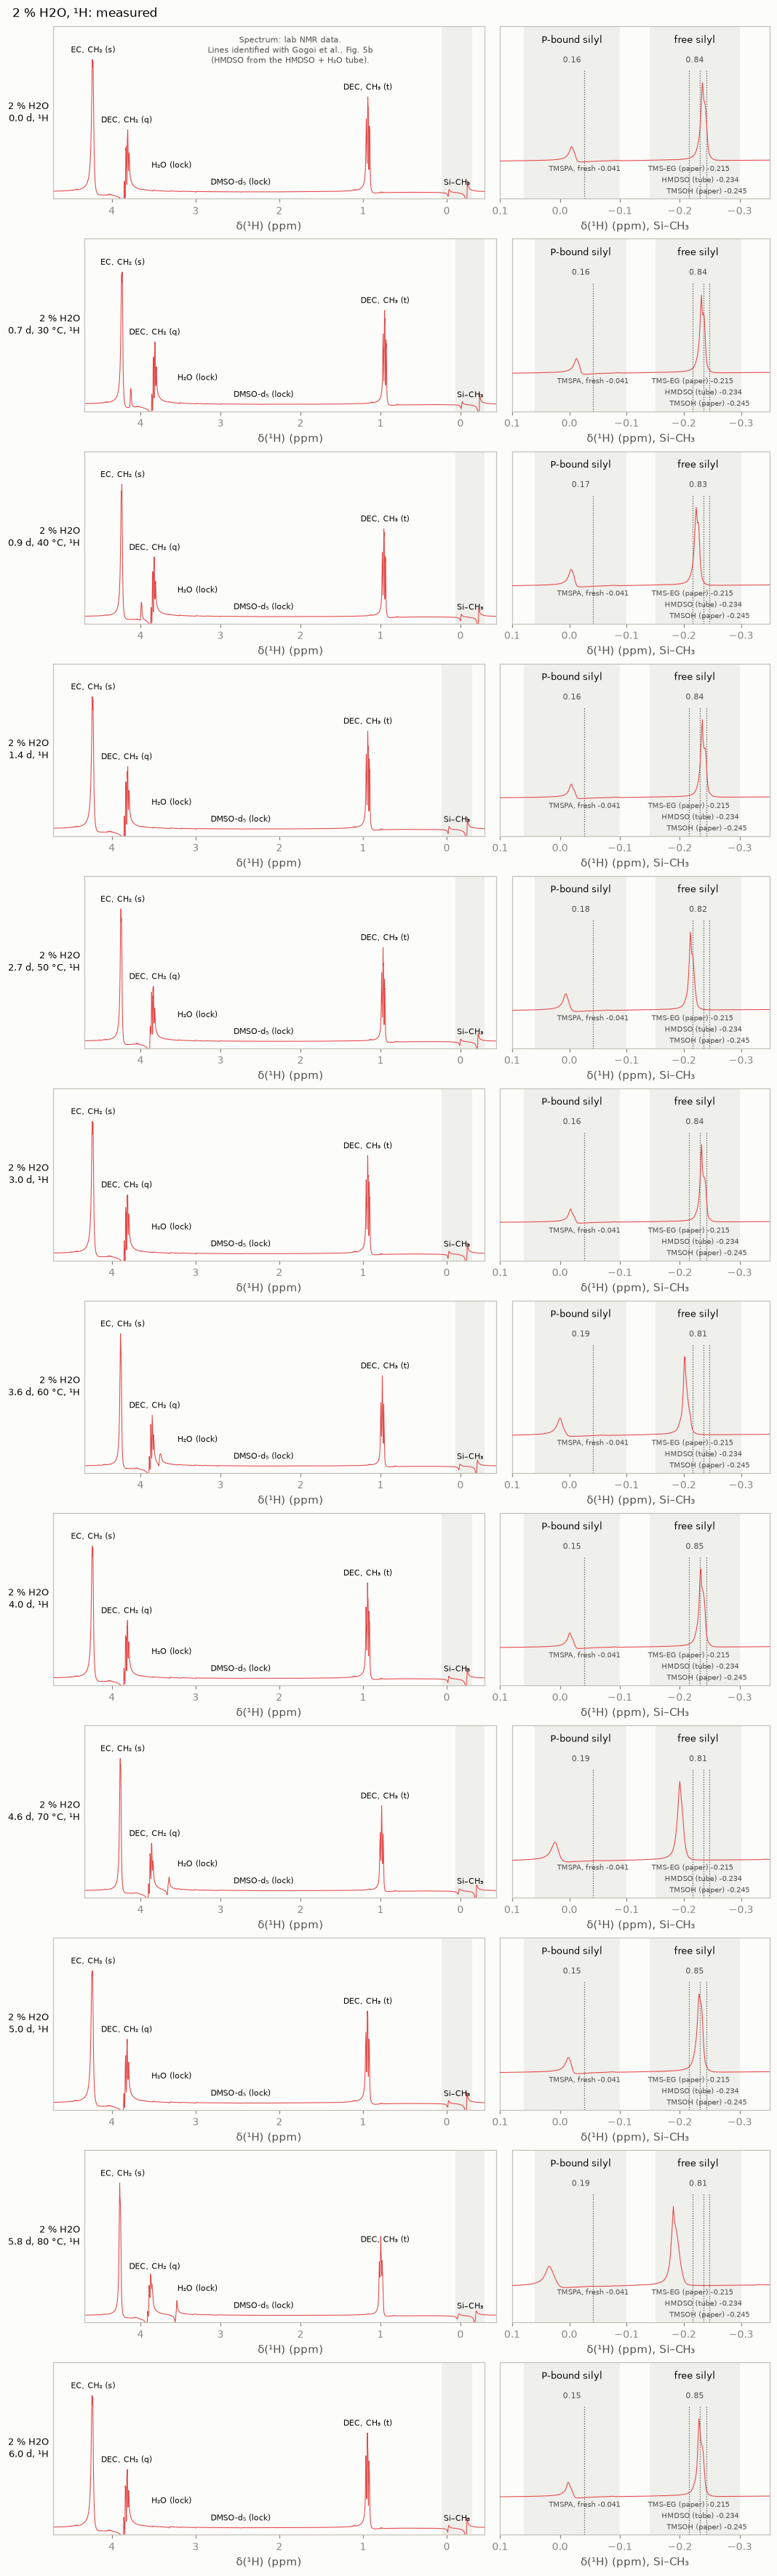

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2022-06-22 18:04:30,free silyl (silyl groups),378.0,21.4,5.7,3672,50,3.26,1,22.5
1H,2022-06-23 10:30:25,free silyl (silyl groups),375.3,20.5,5.5,3529,64,3.25,1,30.0
1H,2022-06-23 15:22:38,free silyl (silyl groups),371.8,20.1,5.4,3230,64,3.27,1,40.0
1H,2022-06-24 03:04:20,free silyl (silyl groups),377.6,21.8,5.8,4178,64,3.25,1,22.4
1H,2022-06-25 11:22:23,free silyl (silyl groups),367.8,19.9,5.4,3205,64,3.25,1,50.0
1H,2022-06-25 18:03:49,free silyl (silyl groups),377.9,21.5,5.7,4425,64,3.27,1,22.5
1H,2022-06-26 09:36:07,free silyl (silyl groups),364.6,21.8,6.0,2806,64,3.27,1,60.0
1H,2022-06-26 18:04:16,free silyl (silyl groups),379.2,21.4,5.7,3614,64,3.25,1,22.6
1H,2022-06-27 07:57:47,free silyl (silyl groups),362.9,26.7,7.4,2237,64,3.27,1,70.0
1H,2022-06-27 18:04:20,free silyl (silyl groups),381.8,21.0,5.5,3146,64,3.25,1,22.9


In [4]:
show_folder(['5% TMSPa + 2v% H2O in EC-DEC/Ramping Temperature', '5% TMSPa + 2v% H2O in EC-DEC/After Ramping Temperature'])

#### 1.1.3 `5v%TMSPa + 2v%TMSOH`

`TMSPa + TMSOH (A)`. The file named `_19F` is a ²⁹Si spectrum (its header).

#### A. ³¹P

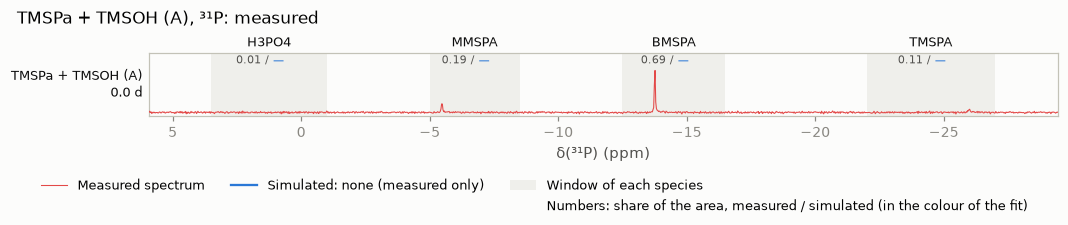

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2023-05-15 17:06:48,BMSPA,102.7,8.4,8.2,38,16,5.69,5,21.7


#### B. ²⁹Si

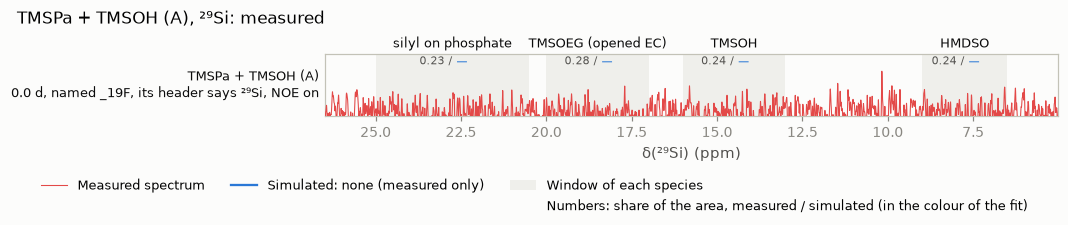

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-15 17:10:08,TMSOEG (silyl groups),175.1,28.4,16.2,3,256,10.34,5,21.6


#### C. ¹H

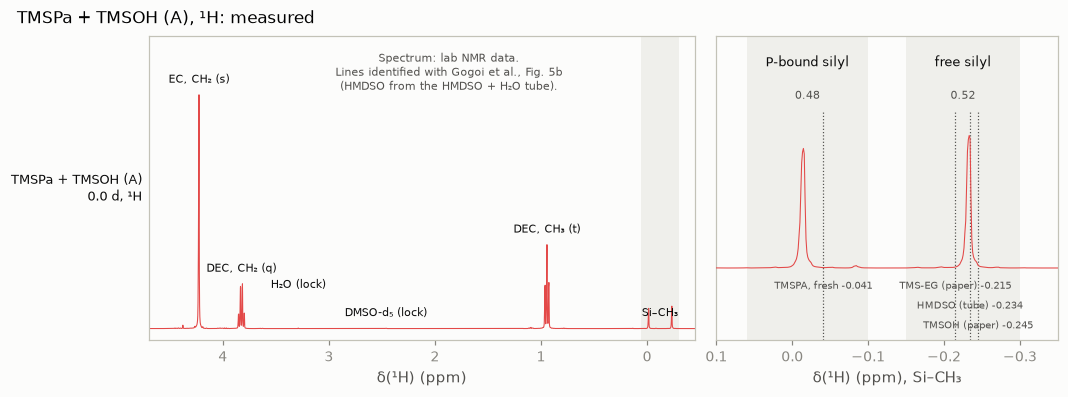

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-15 17:03:07,free silyl (silyl groups),324.4,0.5,0.1,2671,16,7.81,5,21.7


In [5]:
show_folder('5v%TMSPa+2v%TMSOH in ECDEC')

#### 1.1.4 `5v% TMSOH + 2v% H2O`

Not a fitted tube; no phosphate, so ¹H has only the window of the free silyl.

#### A. ²⁹Si

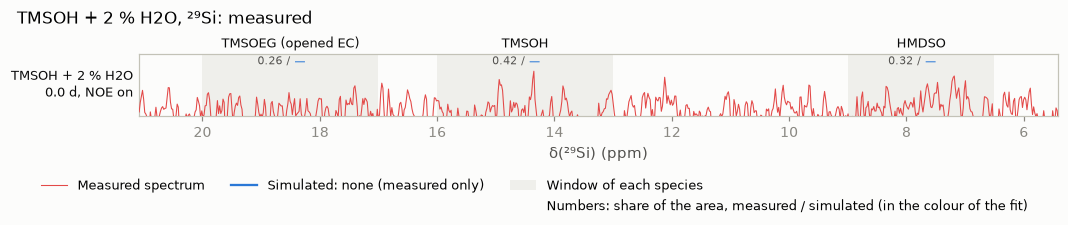

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-17 17:10:12,TMSOH,188.5,22.9,12.2,3,6000,5.66,5,21.9


#### B. ¹H

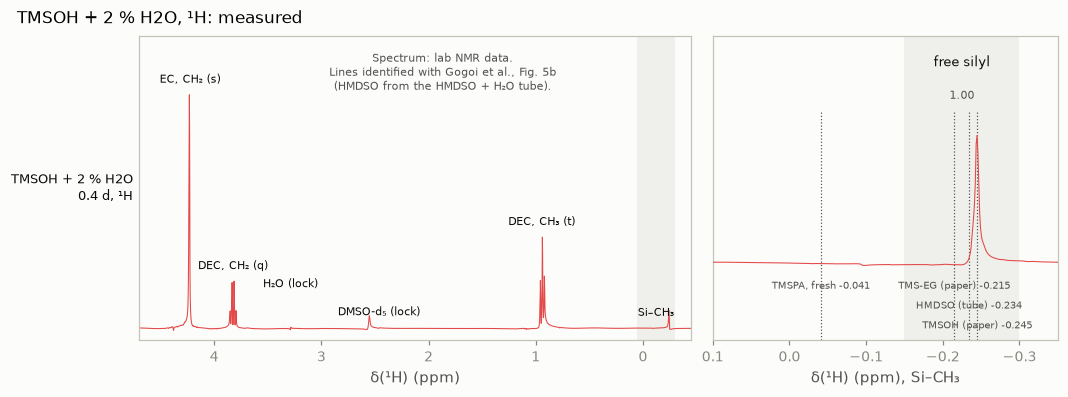

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-18 02:36:59,free silyl (silyl groups),449.6,0.0,0.0,3219,16,3.44,1,21.9


,,share,σ
,window,free silyl,free silyl
tube,days,,
TMSOH + 2 % H2O,0.39,1.000,0.000


In [6]:
show_folder('5v% TMSOH+2v% H2O in ECDEC')

#### 1.1.5 `5v%TMSOTMS + 2v%H2O`

Not a fitted tube; no phosphate, so ¹H has only the window of the free silyl.

#### A. ²⁹Si

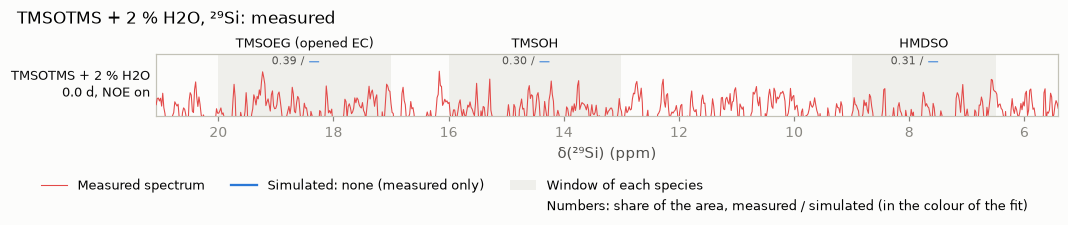

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-18 17:06:56,TMSOEG (silyl groups),181.5,26.6,14.6,3,6000,5.66,5,22.2


#### B. ¹H

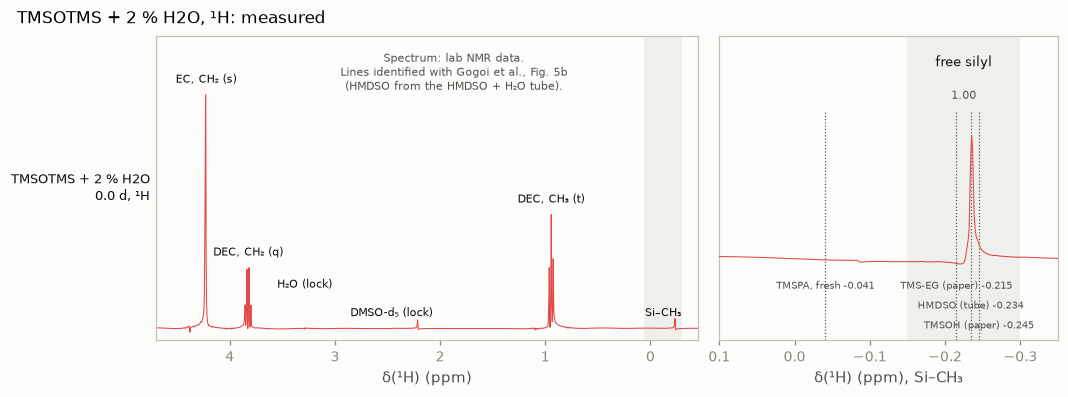

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-18 17:04:17,free silyl (silyl groups),470.5,0.0,0.0,2805,16,3.44,1,22.2


,,share,σ
,window,free silyl,free silyl
tube,days,,
TMSOTMS + 2 % H2O,0.00,1.000,0.000


In [7]:
show_folder('5v%TMSOTMS+2v%H2O in ECDEC')

---
### 1.2 Concentration plots

In [8]:
# §2: the measured concentrations of a tube in the four panels of NB05 (demo.reactor_plots.CONCENTRATION_PANELS), no model
from demo.reactor_plots import CONCENTRATION_PANELS
from matplotlib.lines import Line2D

NUCLEUS_MARKERS = {'31P': 'o', '13C': 'D', '29Si': '^', '1H': 's'}
PANEL_OF_WINDOW = {'TMSPA': 0, 'BMSPA': 0, 'MMSPA': 0, 'H3PO4': 0, 'TMSOH': 1, 'HMDSO': 1, 'P-silyl': 1, 'P-bound silyl': 1,
                   'free silyl': 1, 'TMSOEG': 3}
GROUP_COLOURS = {'P-silyl': style.SERIES[6], 'P-bound silyl': style.SERIES[6], 'free silyl': style.SERIES[4], 'TMSOEG': fit_plots.INK_MUTED}
GROUP_LABELS = {'P-silyl': 'silyl on phosphate (silyl groups)', 'P-bound silyl': 'silyl on phosphate (silyl groups)',
                'free silyl': 'free silyl (silyl groups)', 'TMSOEG': 'TMSOEG + TMSOdiEG'}


def tabulate_concentrations(folders):
    # One row per window of every spectrum of the folders: concentration ± σ (mM), the spectrum's S/N, time and temperature
    files = list_folder(folders)
    shares, _ = tabulate_folder(files)
    rows = []
    for path, spectrum in shares.groupby('path', sort=False):
        tube, nucleus = spectrum['tube'].iloc[0], spectrum['nucleus'].iloc[0]
        members, c0 = SHARE_SPECIES[nucleus], mixing_c0(tube)
        total = sum(n * c0.get(sp, 0.0) for window in spectrum['window'] for sp, n in members[window].items())
        sn = signal_to_noise(path, nucleus, axis_offset(tube, nucleus))
        for _, r in spectrum.iterrows():
            species = members[r['window']]
            n = next(iter(species.values())) if len(species) == 1 else 1
            rows.append({'tube': tube, 'nucleus': nucleus, 'window': r['window'], 't_h': r['t_h'], 'T_C': r['T_C'], 'S/N': sn,
                         'windows': len(spectrum), 'conc_mM': 1000 * r['measured'] * total / n,
                         'sigma_mM': 1000 * np.hypot(r['sigma_noise'], r['sigma_baseline']) * total / n})
    return pd.DataFrame(rows)


def draw_concentrations(points, title, fig=None):
    # The four panels of NB05 with the measured points only; a temperature strip above them if a spectrum was taken hot.
    # fig: a figure or subfigure to draw into (default: a new figure)
    hot = (points['T_C'] >= RT_MAX_C).any()
    if fig is None:
        fig = plt.figure(figsize=(12, 8.4 if hot else 7.4), layout='constrained')
    grid = fig.add_gridspec(3 if hot else 2, 2, height_ratios=[0.4, 2, 2] if hot else [1, 1])
    axes = [fig.add_subplot(grid[(1 if hot else 0) + k // 2, k % 2]) for k in range(4)]
    span = max(float(points['t_h'].max() - min(points['t_h'].min(), 0.0)), 1.0)
    start, end = min(0.0, float(points['t_h'].min())) - 0.03 * span, float(points['t_h'].max()) + 0.03 * span
    if hot:
        spectra = points.drop_duplicates(['t_h', 'nucleus']).sort_values('t_h')
        for col in range(2):
            strip = fig.add_subplot(grid[0, col], sharex=axes[col])
            strip.plot(spectra['t_h'], spectra['T_C'], 'o', color=fit_plots.INK_MUTED, markersize=3.5)
            strip.set_ylabel('T (°C)')
            strip.tick_params(labelbottom=False)
    for k, (ax, (panel, species)) in enumerate(zip(axes, CONCENTRATION_PANELS)):
        mine = points[points['window'].map(PANEL_OF_WINDOW) == k]
        handles = {}
        for (window, nucleus), seen in mine.groupby(['window', 'nucleus'], sort=False):
            colour = GROUP_COLOURS[window] if window in GROUP_COLOURS else style.SERIES[species.index(window)]
            ax.errorbar(seen['t_h'], seen['conc_mM'], yerr=seen['sigma_mM'], fmt=NUCLEUS_MARKERS[nucleus], color=colour,
                        markersize=5.5, markeredgecolor=fit_plots.SURFACE, markeredgewidth=0.8, elinewidth=1.0, capsize=3, zorder=4)
            label = GROUP_LABELS.get(window, window)
            handles.setdefault(label, Line2D([], [], color=colour, marker='o', linestyle='none', markersize=6, label=label))
        if mine.empty:
            ax.set_yticks([])
            ax.text(0.5, 0.5, 'no NMR points', transform=ax.transAxes, ha='center', va='center', fontsize=9, color=fit_plots.INK_MUTED)
        else:
            low = float((mine['conc_mM'] - mine['sigma_mM']).min())
            ax.set_ylim(min(0.0, 1.08 * low), 1.08 * float((mine['conc_mM'] + mine['sigma_mM']).max()))
            ax.legend(handles=list(handles.values()), loc='best')
        ax.set_xlim(start, end)
        ax.set_title(panel, loc='left')
        ax.set_ylabel('Concentration (mM)')
        ax.set_xlabel('Time since the first spectrum of the tube (h)')
    shapes = [Line2D([], [], color=fit_plots.INK_MUTED, marker=m, linestyle='none', markersize=6, label=f'{fit_plots.NUCLEUS_LABELS[n]} (measured, ± σ)')
              for n, m in NUCLEUS_MARKERS.items() if n in set(points['nucleus'])]
    fig.legend(handles=shapes, loc='outside lower center', ncols=len(shapes))
    fig.suptitle(title, x=0.01, ha='left', fontsize=11)
    return fig


def show_concentrations(folders, sn_ratio):
    # A tube of §1: its points with S/N ≥ sn_ratio (the others printed as noise), in the four panels
    points = tabulate_concentrations(folders)
    noise = points[points['S/N'] < sn_ratio].drop_duplicates(['nucleus', 't_h'])
    for _, r in noise.iterrows():
        print(f"noise, not plotted: {fit_plots.NUCLEUS_LABELS[r['nucleus']]} at {r['t_h']:.1f} h, S/N {r['S/N']:.0f}")
    single = points[(points['windows'] == 1) & (points['S/N'] >= sn_ratio)].drop_duplicates(['nucleus', 't_h'])
    for _, r in single.iterrows():
        print(f"one window only, not plotted: {fit_plots.NUCLEUS_LABELS[r['nucleus']]} at {r['t_h']:.1f} h")
    shown = points[(points['S/N'] >= sn_ratio) & (points['windows'] > 1)]
    if shown.empty:
        print('nothing to plot above the noise limit')
        return
    fig = draw_concentrations(shown, f"{shown['tube'].iloc[0]}: measured concentrations (S/N ≥ {sn_ratio:g})")
    display(fig)
    plt.close(fig)

#### 1.2.1 `5% TMSPa + 0.5v% H2O`

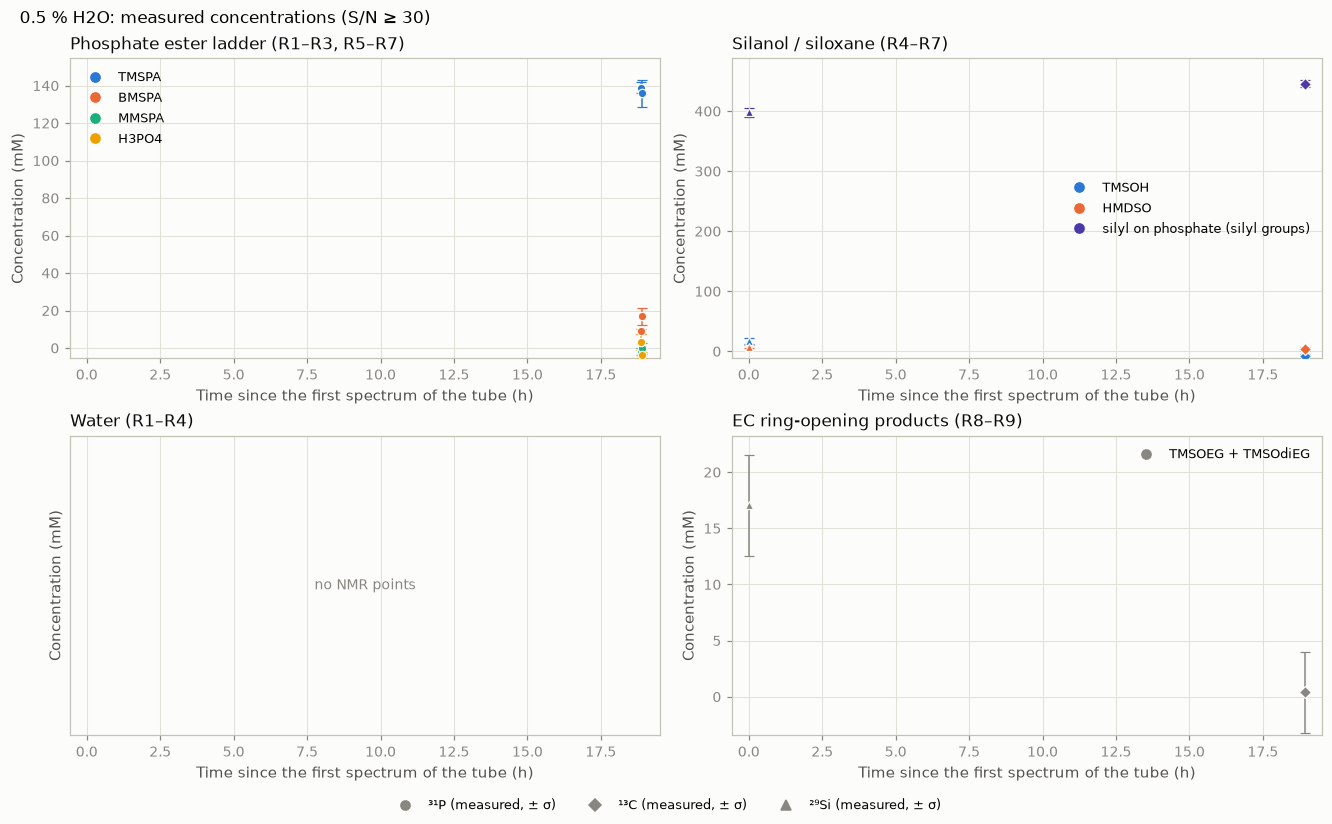

In [9]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations('5% TMSPa + 0.5v% H2O in EC-DEC', SN_RATIO)

#### 1.2.2 `5% TMSPa + 2v% H2O`

noise, not plotted: ²⁹Si at 0.2 h, S/N 18
noise, not plotted: ²⁹Si at 33.6 h, S/N 24
noise, not plotted: ²⁹Si at 72.6 h, S/N 22
noise, not plotted: ²⁹Si at 96.6 h, S/N 24
noise, not plotted: ²⁹Si at 145.6 h, S/N 28


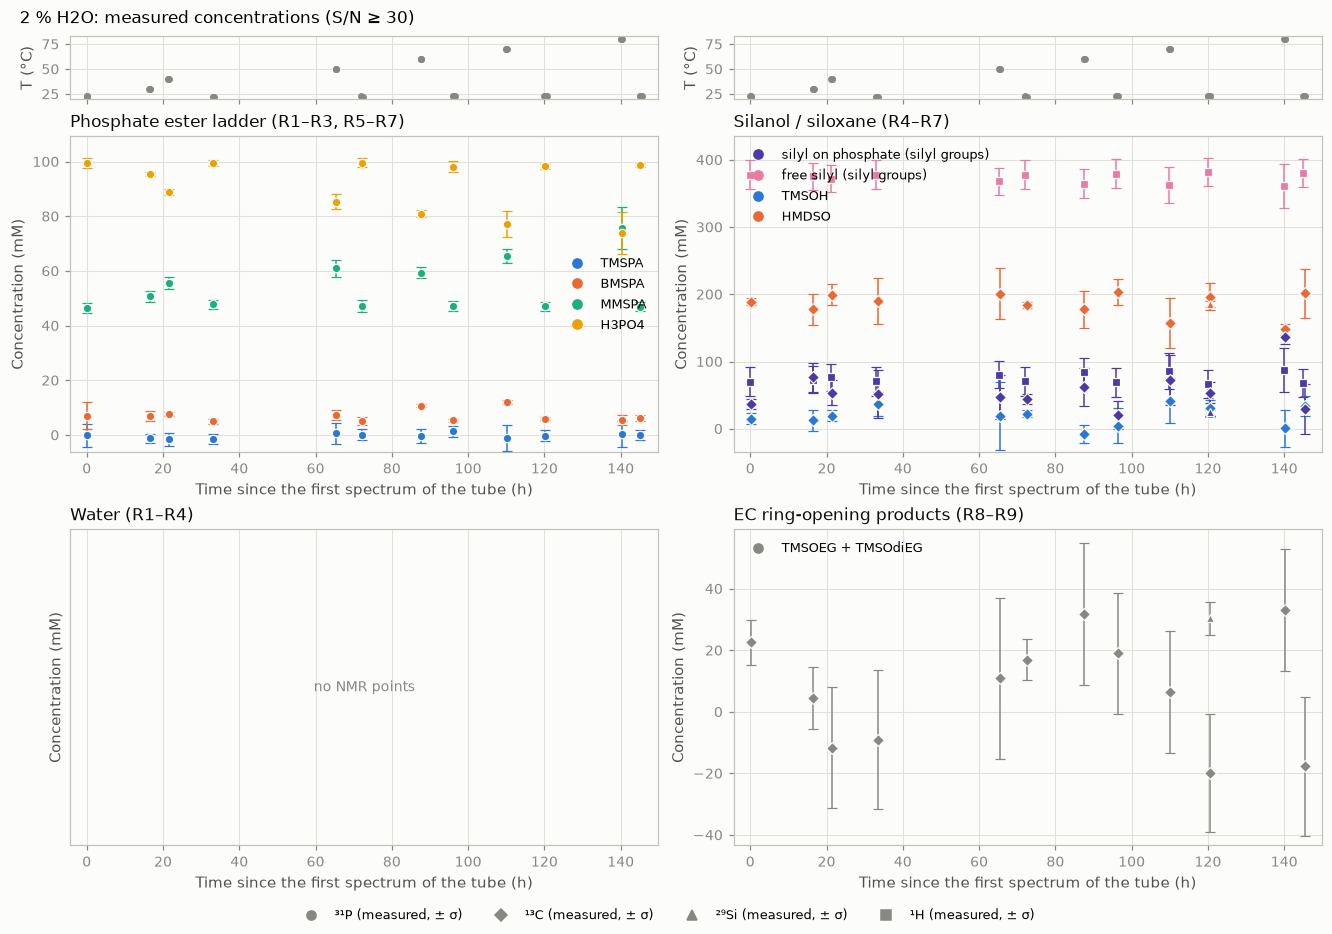

In [10]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations(['5% TMSPa + 2v% H2O in EC-DEC/Ramping Temperature', '5% TMSPa + 2v% H2O in EC-DEC/After Ramping Temperature'], SN_RATIO)

#### 1.2.3 `5v%TMSPa + 2v%TMSOH`

noise, not plotted: ²⁹Si at 0.1 h, S/N 3


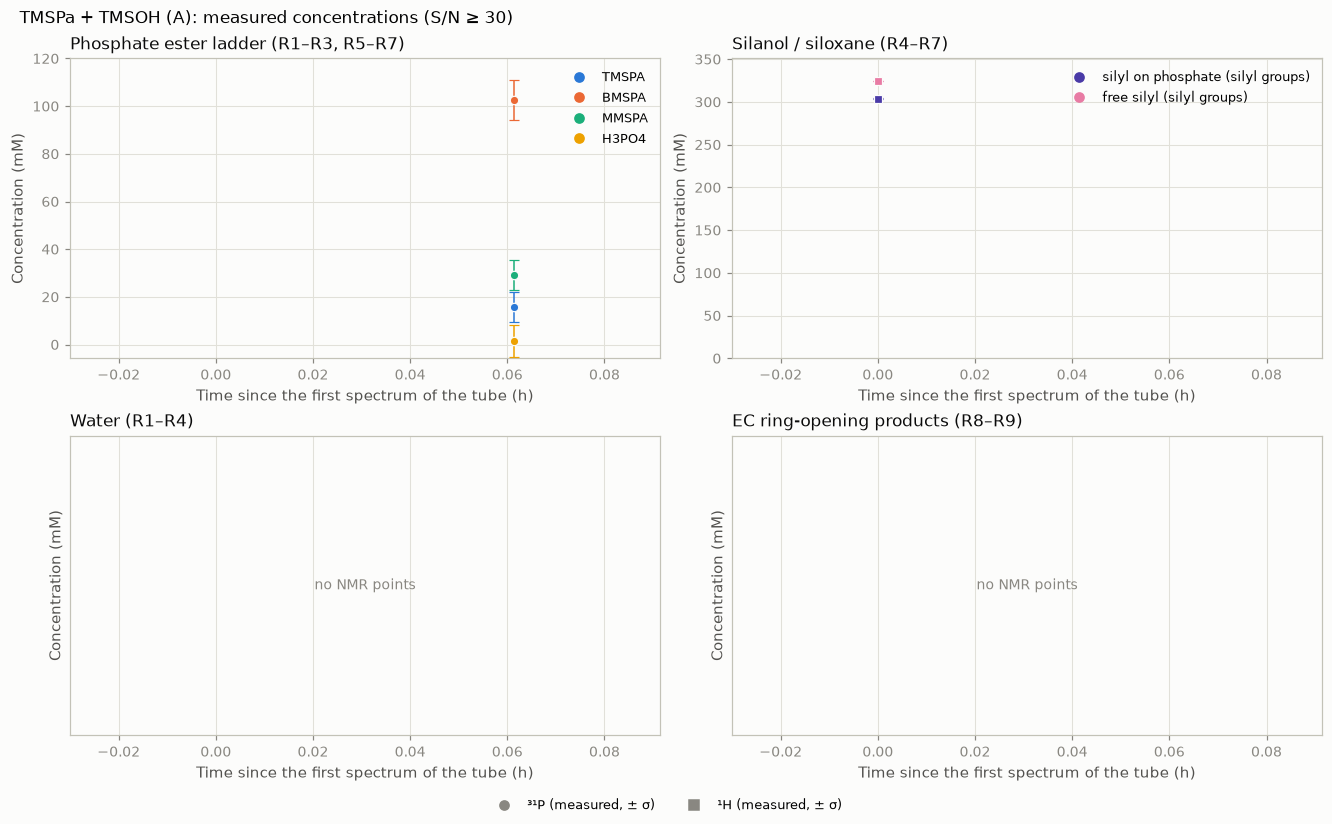

In [11]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations('5v%TMSPa+2v%TMSOH in ECDEC', SN_RATIO)

#### 1.2.4 `5v% TMSOH + 2v% H2O`

one window only, not plotted: ¹H at 9.4 h


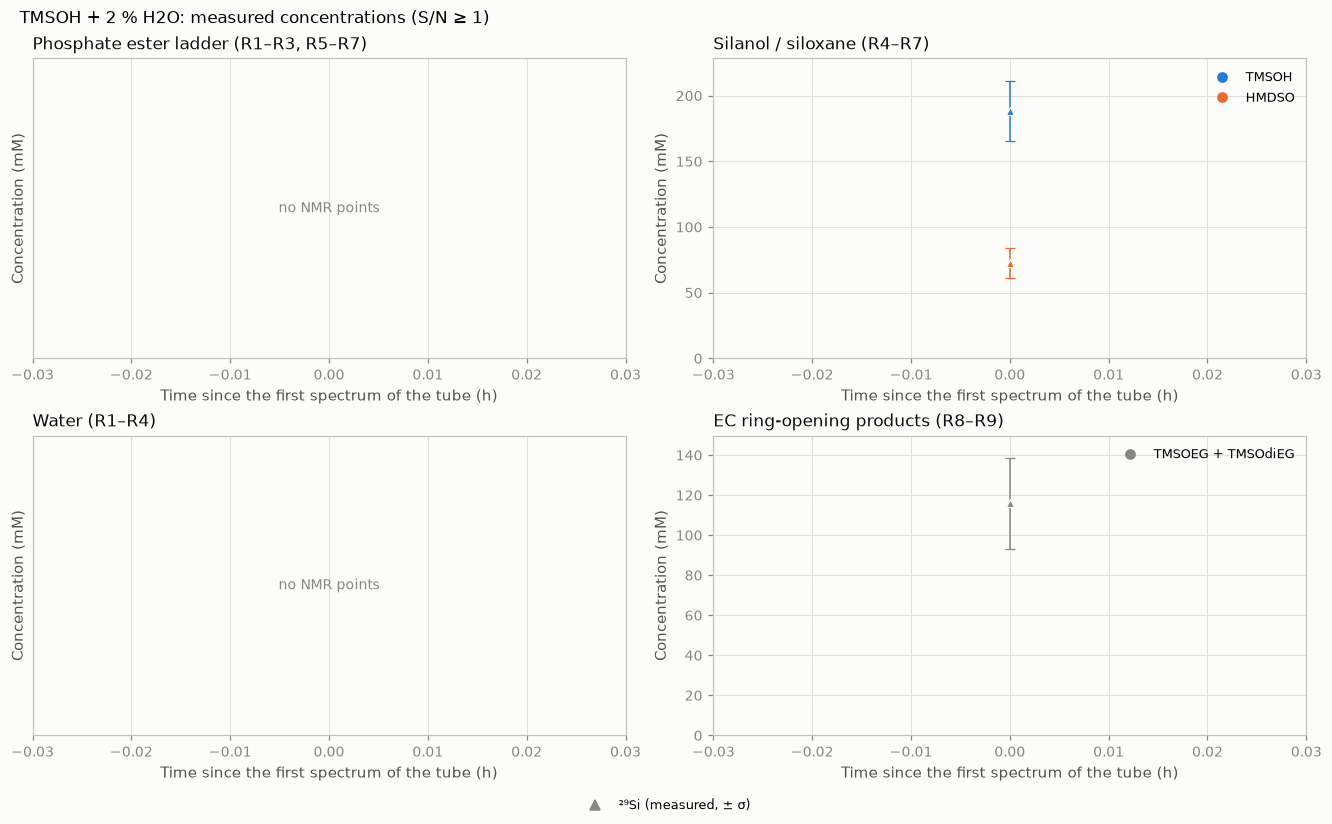

In [12]:
SN_RATIO = 1      # S/N below this: noise, not plotted
show_concentrations('5v% TMSOH+2v% H2O in ECDEC', SN_RATIO)

#### 1.2.5 `5v%TMSOTMS + 2v%H2O`

one window only, not plotted: ¹H at 0.0 h


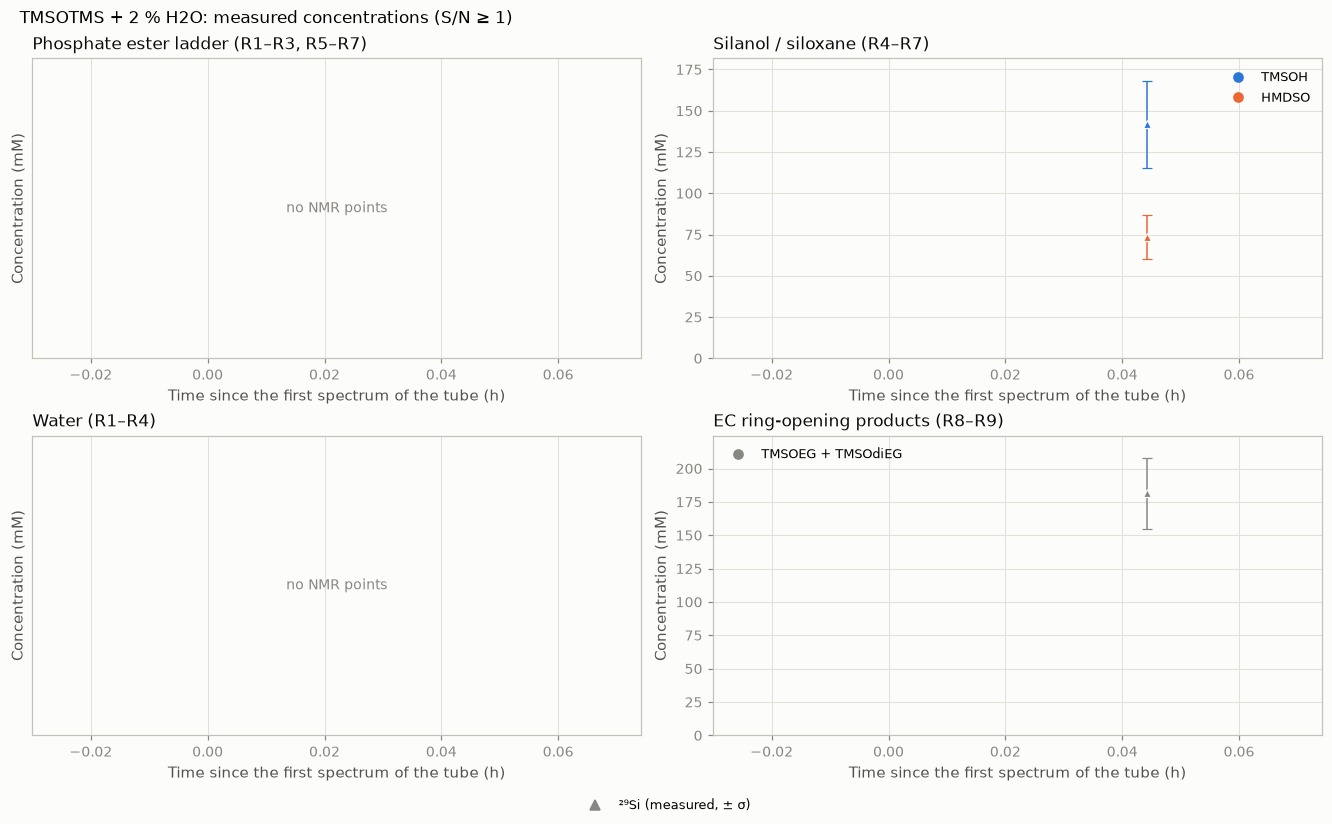

In [13]:
SN_RATIO = 1      # S/N below this: noise, not plotted
show_concentrations('5v%TMSOTMS+2v%H2O in ECDEC', SN_RATIO)

---
### 1.3 The 10-day experiments

Three folders of spectra taken on 25–26 May 2023, about ten days after the first spectra of each tube. Nothing is simulated: each figure shows the measured spectrum, the window of each species (grey) and its measured share of the area of the windows (²⁹Si: of the heights). Time: days since the first spectrum of the same tube.

- **Per nucleus (A, B, …):** as in §1: its figure, then its tables (files; measured shares ± σ).

#### 1.3.1 `5v%TMSOTMS + 2v%H2O`, after 10 days

The folder holds the ¹H of two tubes, both without phosphate (title of each file): TMSOH + 2 % H₂O and TMSOTMS (HMDSO) + 2 % H₂O. Neither is a fitted tube. With no phosphate there is only the window of the free silyl, so its share is 1: what the figure shows is where the Si–CH₃ line sits against TMSOH and HMDSO.

#### A. ¹H

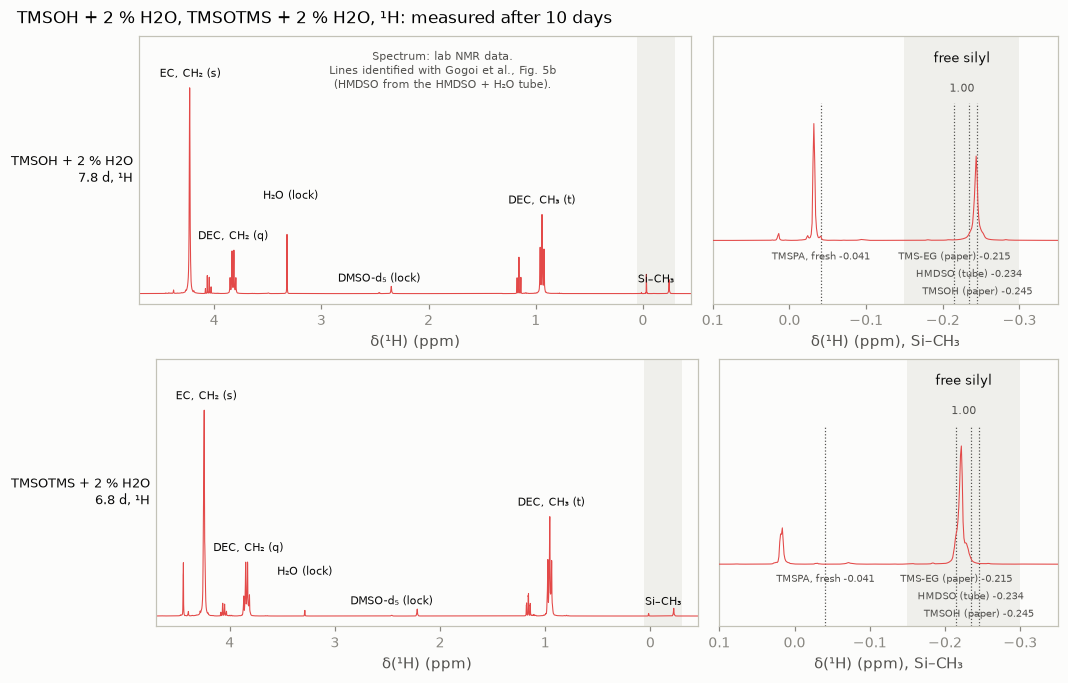

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-25 13:00:50,free silyl (silyl groups),449.6,0.0,0.0,3490,16,7.81,5,21.7
1H,2023-05-25 13:06:17,free silyl (silyl groups),470.5,0.0,0.0,2740,16,7.81,5,21.7


,,share,σ
,window,free silyl,free silyl
tube,days,,
TMSOH + 2 % H2O,7.83,1.000,0.000
TMSOTMS + 2 % H2O,6.83,1.000,0.000


In [14]:
show_folder('NG230525_5v%TMSOTMS+2v%H2O in EC_DEC_AFTER 10 DAYS', ' after 10 days')

#### 1.3.2 `5v%TMSPa`, after 10 days

`TMSPa alone`: ³¹P and ¹H.

#### A. ³¹P

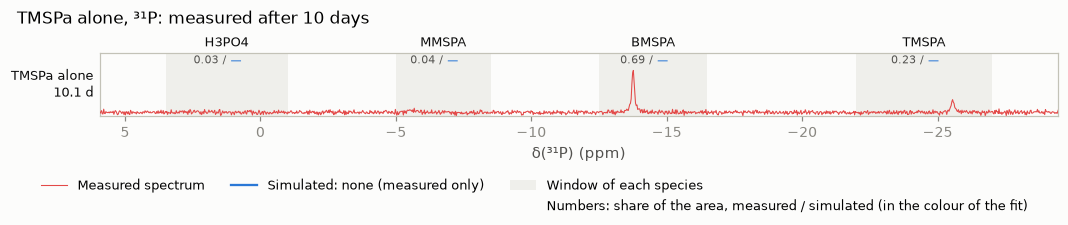

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2023-05-25 12:55:55,BMSPA,102.8,7.2,7.0,16,16,5.69,5,21.7


#### B. ¹H

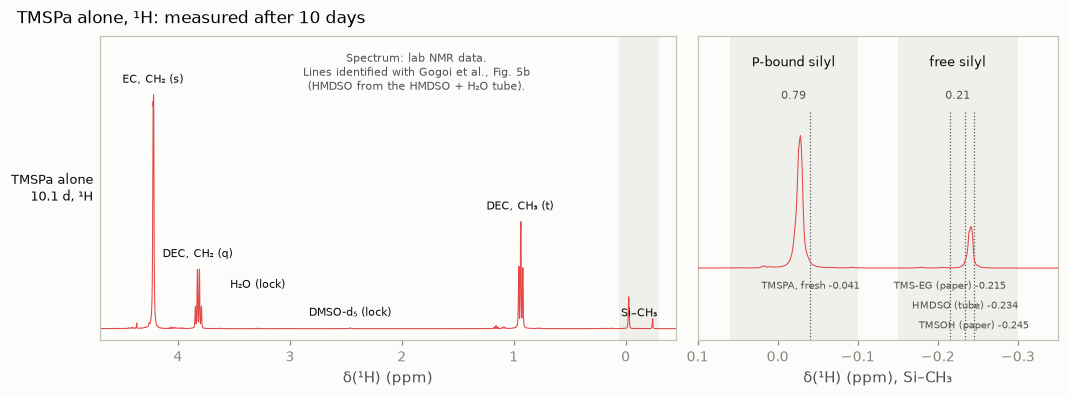

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-25 12:53:37,P-bound silyl (silyl groups),355.9,0.8,0.2,2859,16,7.81,5,21.7


In [15]:
show_folder('NG230525_5v%TMSPa in EC_DEC_AFTER 10 DAYS', ' after 10 days')

#### 1.3.3 `5v%TMSPa + 2v%TMSOH`, after 10 days

`TMSPa + TMSOH (A)`: ¹³C and ¹H on 25 May; ¹H and ²⁹Si (INEPT) the next day, in files titled 5v% TMSPa + 5v% TMSOH.

#### A. ¹³C

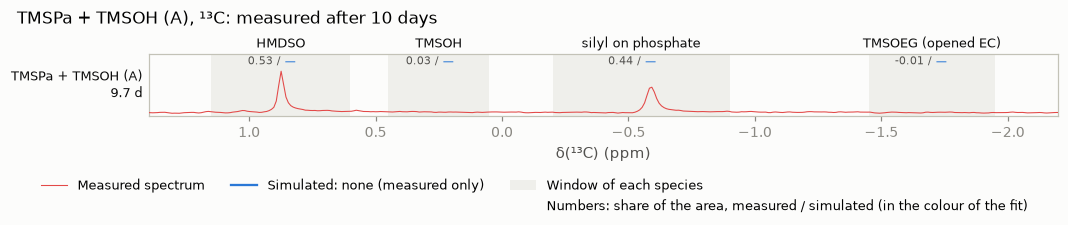

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
13C,2023-05-25 11:00:38,HMDSO,168.0,10.3,6.1,135,1024,3.06,2,21.7


#### B. ²⁹Si

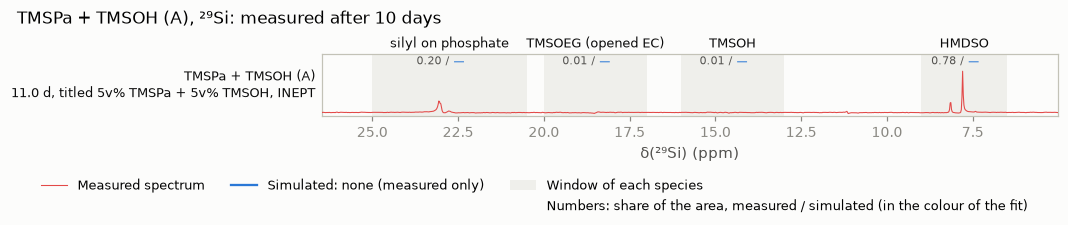

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
29Si,2023-05-26 18:08:20,HMDSO,245.5,0.6,0.2,295,2500,2.76,2,21.8


#### C. ¹H

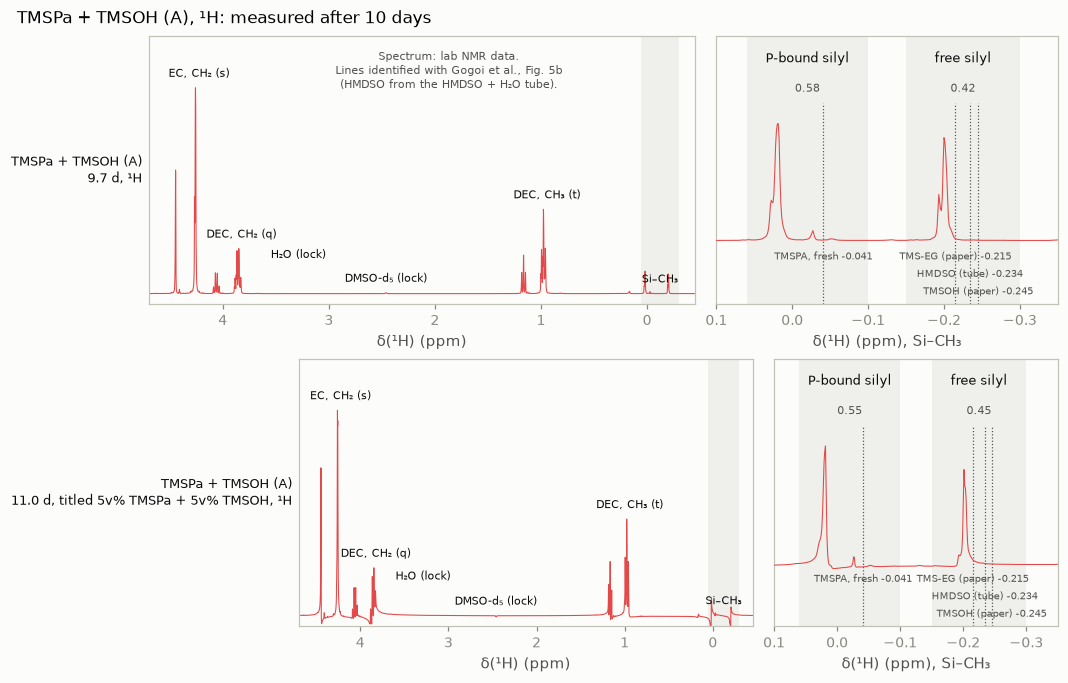

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2023-05-25 10:58:19,P-bound silyl (silyl groups),361.6,2.9,0.8,1497,16,7.81,5,21.9
1H,2023-05-26 18:04:54,P-bound silyl (silyl groups),345.6,3.9,1.1,1392,16,6.69,4,22.0


In [16]:
show_folder('NG230525_5v%TMSPa+2v%TMSOH in EC_DEC_AFTER 10 DAYS', ' after 10 days')

## 2. NMR - 05/11/2026

In [31]:
# The spectra of 5 Nov 2026 (5 % TMSPa + 2 % H2O in EC/DEC), their folder beside the raw data of §1, added to the inventory
# as a tube of its own. Time zero: the water added to the TMSPa, 6 min 50 s before the end of the first ³¹P spectrum.
# Composition at mixing: that of the 2 % H2O tube (same recipe)
NEW_NMR_ROOT = lab_nmr_dir().parent / 'nmr_261105'
NEW_FOLDER = 'nmr_261105_5%TMSPa_2%H2O_ECDEC_1_1'
NEW_TUBE = '2 % H2O, 05/11/2026'
new_files = build_lab_nmr_inventory(NEW_NMR_ROOT)
first_31p = new_files[new_files['nucleus'] == '31P'].sort_values('acquired_at').iloc[0]
WATER_ADDED = first_31p['acquired_at'] + pd.Timedelta(minutes=first_31p['duration_min']) - pd.Timedelta(minutes=6, seconds=50)
INVENTORY_ALL = pd.concat([INVENTORY_ALL[INVENTORY_ALL['folder'] != NEW_FOLDER], new_files], ignore_index=True)
TUBES[NEW_TUBE] = {'first': [NEW_FOLDER], 'phosphate': True, 'observables': '2 % H2O', 't0': WATER_ADDED}
TUBE_OF_FOLDER[NEW_FOLDER] = NEW_TUBE
print(f'{NEW_NMR_ROOT / NEW_FOLDER}: {len(new_files)} files; water added {WATER_ADDED:%Y-%m-%d %H:%M:%S}')

/home/yeray/data/nmr_261105/nmr_261105_5%TMSPa_2%H2O_ECDEC_1_1: 11 files; water added 2026-11-05 16:33:04


---
### 2.1 Reaction experiments

#### 2.1.1 `5% TMSPa + 0.5v% H2O`

#### 2.1.2 `5% TMSPa + 2v% H2O`

#### A. ³¹P

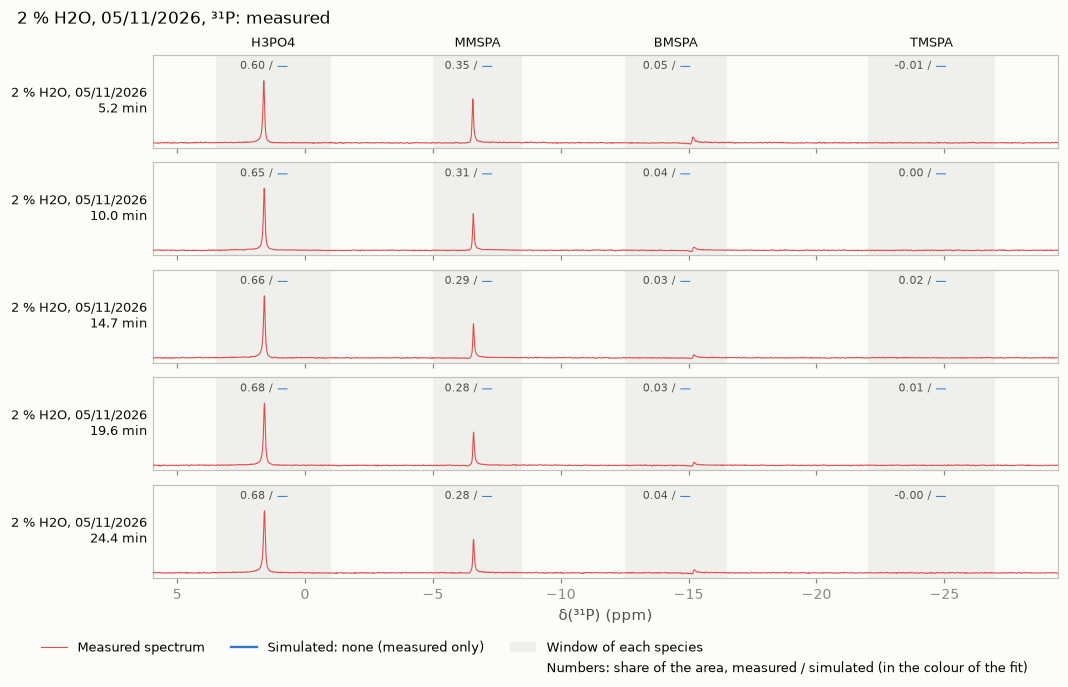

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
31P,2026-11-05 16:38:15,H3PO4,89.7,3.8,4.3,120,16,6.19,5,22.3
31P,2026-11-05 16:43:05,H3PO4,97.6,1.3,1.3,128,16,6.19,5,22.3
31P,2026-11-05 16:47:44,H3PO4,99.3,1.0,1.0,124,16,6.25,5,22.3
31P,2026-11-05 16:52:37,H3PO4,101.3,4.3,4.3,121,16,6.19,5,22.3
31P,2026-11-05 16:57:26,H3PO4,101.7,1.6,1.6,114,16,6.25,5,22.2


#### B. ¹H

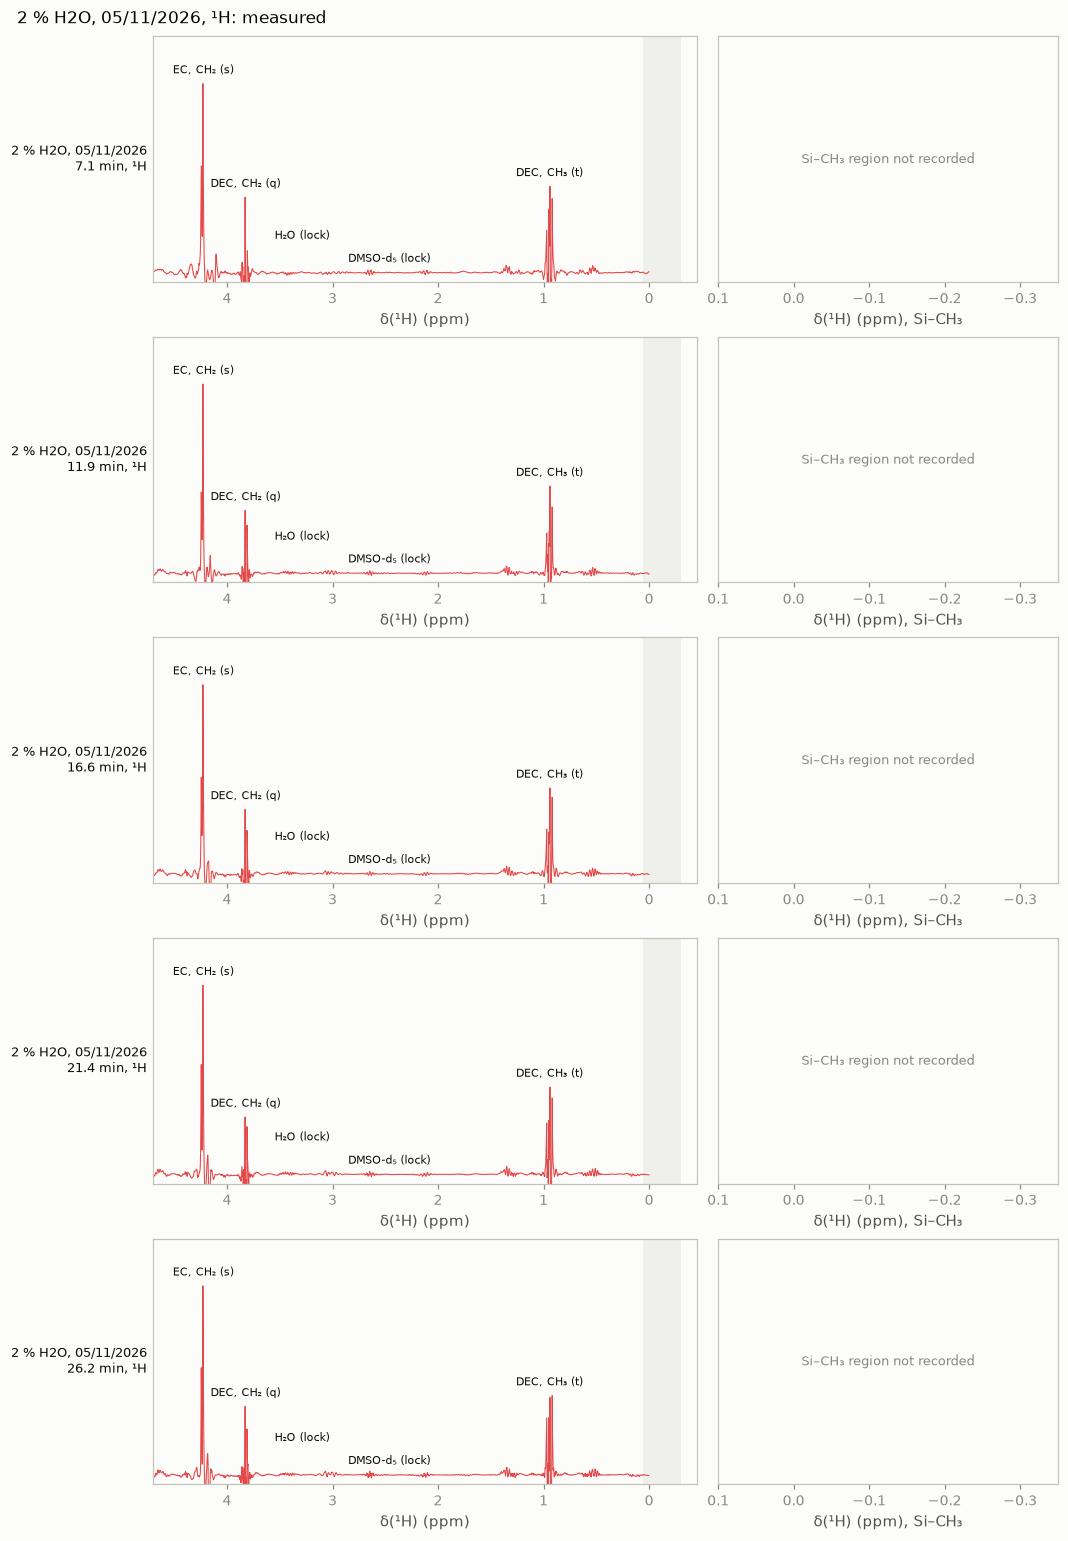

nucleus,acquired,species,conc. (mM),σ (mM),σ (%),S/N,scans,time per scan (s),delay d1 (s),T (°C)
1H,2026-11-05 16:40:07,,nan,nan,nan,3,8,6.88,5,22.3
1H,2026-11-05 16:44:57,,nan,nan,nan,3,8,6.88,5,22.3
1H,2026-11-05 16:49:37,,nan,nan,nan,3,8,6.88,5,22.3
1H,2026-11-05 16:54:28,,nan,nan,nan,7,8,6.88,5,22.3
1H,2026-11-05 16:59:18,,nan,nan,nan,7,8,6.88,5,22.2


tube,days


In [18]:
show_folder(NEW_FOLDER)

#### 2.1.3 `5v%TMSPa + 2v%TMSOH`

#### 2.1.4 `5v% TMSOH + 2v% H2O`

#### 2.1.5 `5v%TMSOTMS + 2v%H2O`

---
### 2.2 Concentration plots

#### 2.2.1 `5% TMSPa + 0.5v% H2O`

#### 2.2.2 `5% TMSPa + 2v% H2O`

noise, not plotted: ¹H at 0.1 h, S/N 3
noise, not plotted: ¹H at 0.2 h, S/N 3
noise, not plotted: ¹H at 0.3 h, S/N 3
noise, not plotted: ¹H at 0.4 h, S/N 7
noise, not plotted: ¹H at 0.4 h, S/N 7


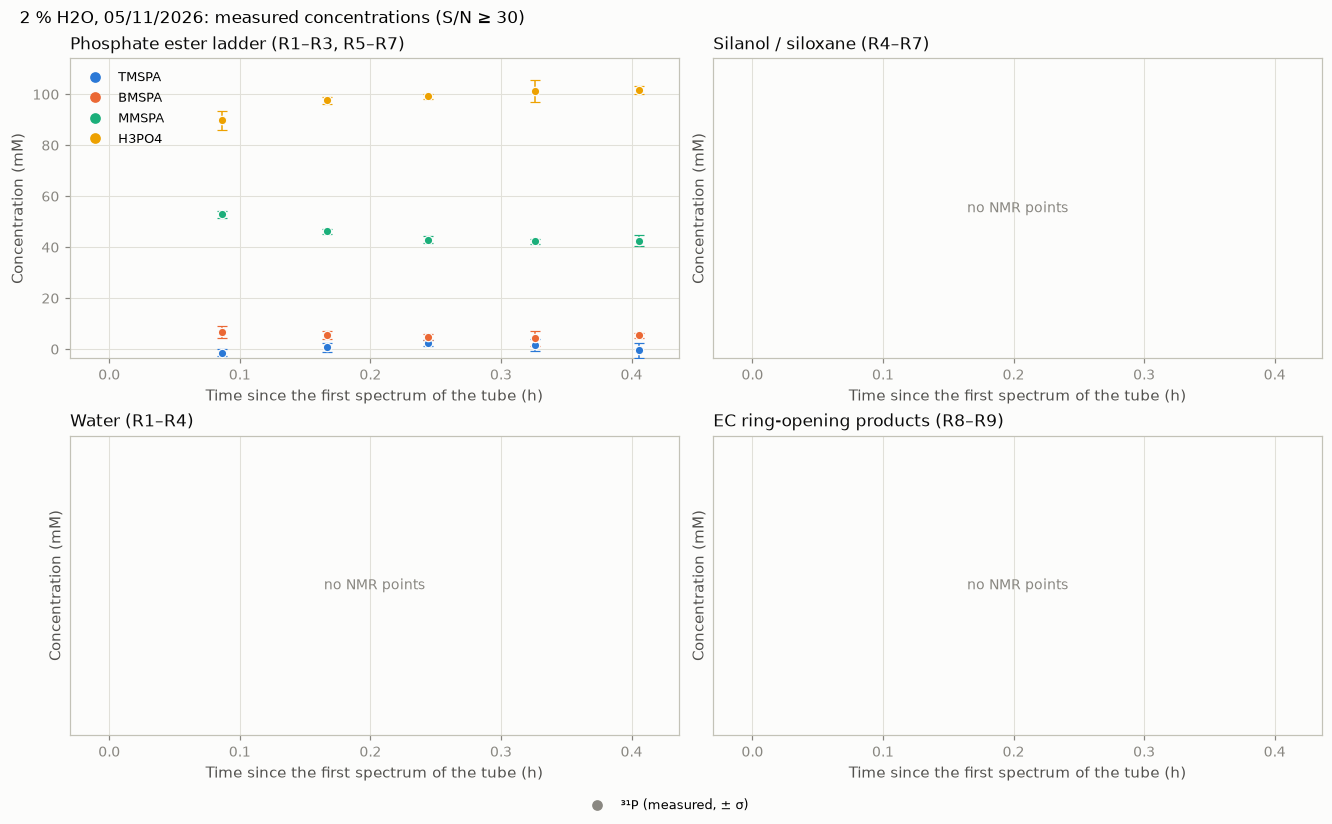

In [19]:
SN_RATIO = 30      # S/N below this: noise, not plotted
show_concentrations(NEW_FOLDER, SN_RATIO)

In [32]:
# Every window of every spectrum of the folder: concentration ± σ (mM) and the S/N of its spectrum (tabulate_concentrations)
points = tabulate_concentrations(NEW_FOLDER)

# ¹H solvent lines EC and DEC, added as rows. Each window phased on its own (load_spectrum window_ppm); area over the median of
# the empty 2.0-3.4 ppm region; σ_noise = MAD of neighbour differences / √2 × √points × spacing. Windows on the axis of this tube
# (about −0.3 ppm from the textbook shifts). Amounts: EC + DEC conserved = c0 of EC (observables) + DEC of the 1:1 w/w recipe
H1_SOLVENT_WINDOWS = {'EC (CH2)': ((4.05, 4.40), 4, 'EC'), 'DEC (CH2)': ((3.65, 3.95), 4, 'DEC'), 'DEC (CH3)': ((0.75, 1.05), 6, 'DEC')}
H1_EMPTY_PPM = (2.0, 3.4)
EC_M = mixing_c0(NEW_TUBE)['EC']
DEC_M = EC_M * calculate_molar_mass('EC') / calculate_molar_mass('DEC')      # 1:1 by weight


def solvent_rows(folder):
    rows = []
    for _, f in list_folder(folder).query("nucleus == '1H' and `copy of`.isna()").iterrows():
        moles, sigmas = {}, {}
        for window, ((low, high), n_h, _) in H1_SOLVENT_WINDOWS.items():
            ppm, y = load_spectrum(f['path'], window_ppm=(low - 0.15, high + 0.15))
            empty = y[(ppm > H1_EMPTY_PPM[0]) & (ppm < H1_EMPTY_PPM[1])]
            step = np.diff(empty)
            noise = 1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)
            inside, spacing = (ppm >= low) & (ppm <= high), abs(ppm[1] - ppm[0])
            moles[window] = (y[inside] - np.median(empty)).sum() * spacing / n_h
            sigmas[window] = noise * np.sqrt(inside.sum()) * spacing / n_h
        scale = 1000 * (EC_M + DEC_M) / (moles['EC (CH2)'] + moles['DEC (CH2)'])     # mM per area unit
        for window in H1_SOLVENT_WINDOWS:
            rows.append({'tube': f['tube'], 'nucleus': '1H', 'window': window, 't_h': 24 * f['days'], 'T_C': f['temperature_C'],
                         'S/N': signal_to_noise(f['path'], '1H'), 'windows': len(H1_SOLVENT_WINDOWS),
                         'conc_mM': moles[window] * scale, 'sigma_mM': sigmas[window] * scale})
    return pd.DataFrame(rows)


points = pd.concat([points, solvent_rows(NEW_FOLDER)], ignore_index=True).sort_values(['t_h', 'nucleus'], kind='stable')
table = pd.DataFrame({'time (min)': 60 * points['t_h'], 'Nuclei': points['nucleus'].map(fit_plots.NUCLEUS_LABELS), 'molecule': points['window'],
                      'concentration (mM)': points['conc_mM'], 'error (mM)': points['sigma_mM'],
                      'error (%)': 100 * points['sigma_mM'].abs() / points['conc_mM'].abs(), 'S/N ratio': points['S/N']})
# error (%) coloured in three steps with the coolwarm colours of the z (SD) tables: < 5 % blue, 5-10 % pale, > 10 % red
from matplotlib import cm, colors as mcolors
STEP_COLOURS = [mcolors.to_hex(cm.coolwarm(x)) for x in (0.0, 0.55, 1.0)]
def error_colour(e):
    if pd.isna(e): return ''
    colour = STEP_COLOURS[2] if e > 10 else STEP_COLOURS[1] if e >= 5 else STEP_COLOURS[0]
    return f'background-color: {colour}; color: {"black" if colour == STEP_COLOURS[1] else "white"}'

display(table.style.hide(axis='index')
        .set_caption('5% TMSPa + 2v% H2O')
        .map(error_colour, subset=['error (%)'])
        .format({'time (min)': '{:.1f}', 'concentration (mM)': '{:.1f}', 'error (mM)': '{:.1f}', 'error (%)': '{:.1f}', 'S/N ratio': '{:.0f}'}, na_rep=''))


time (min),Nuclei,molecule,concentration (mM),error (mM),error (%),S/N ratio
5.2,³¹P,TMSPA,-1.4,1.4,101.1,120
5.2,³¹P,BMSPA,6.9,2.4,35.0,120
5.2,³¹P,MMSPA,52.9,1.4,2.6,120
5.2,³¹P,H3PO4,89.7,3.8,4.3,120
7.1,¹H,P-bound silyl,,,,3
7.1,¹H,free silyl,,,,3
7.1,¹H,EC (CH2),9729.4,14.6,0.1,3
7.1,¹H,DEC (CH2),2663.4,13.4,0.5,3
7.1,¹H,DEC (CH3),2819.2,8.9,0.3,3
10.0,³¹P,TMSPA,0.7,1.9,277.7,128


#### 2.2.3 `5v%TMSPa + 2v%TMSOH`

#### 2.2.4 `5v% TMSOH + 2v% H2O`

#### 2.2.5 `5v%TMSOTMS + 2v%H2O`

---
### 2.3 The 10-day experiments

#### 2.3.1 `5v%TMSOTMS + 2v%H2O`, after 10 days

#### 2.3.2 `5v%TMSPa`, after 10 days

#### 2.3.3 `5v%TMSPa + 2v%TMSOH`, after 10 days

# 2. Modelling

## 2.1 Objective function
$Error_{model}=\frac{y_{model}-y_{NMR}}{\sigma_{tot}}$

where:
- $y_NMR:$ is the concentration measured by the NMR
- $y_model:$ is the model prediction

$\sigma_{tot} = \sqrt{\sigma_{noise}^2+\sigma_{baseline}^2}$


$\chi^2 = [\sum_{i,j} Error_{model}^2] = [\sum_{i,j} \frac{y_{model}-y_{NMR}}{\sigma_{tot}}]^2$

The objective funtion is: $\min \chi^2$

## 2.1 Thermo model

$\Delta G_i = \Delta E_{\mathrm{DFT},i} + \Delta E_{\mathrm{solv},i}$

- where $\Delta E_{\mathrm{DFT},i}$ is the pure DFT energy, and

$\Delta E_{\mathrm{solv},i} = \Delta E^{\mathrm{comp}}_{\mathrm{solv},i} \pm \sigma_{\mathrm{solv},i}$

- where $\Delta E^{\mathrm{comp}}_{\mathrm{solv},i}$ is the computed solvation correction and $\sigma_{\mathrm{solv},i}$ is the standard error of the DFT solvent correction. 

The index $i$ runs over the molecules.

So we change $\Delta E_{solv,i} \in [\Delta E_{solv DFT} +- \xi · \sigma_{solv,i}]$

- We change $$\Delta E_{solv,i}$ inside $\xi$ times the standard error (data from simulation)
 

# 3. Fitting thermo

## 3.1 2% water only
2% water is directly fitted from the NMR data

In [21]:
# §3: the helpers of every fit of this section, then the run of §3.1 (thermo2_2pctH2O: 2 % H2O alone)
#   load_thermo_run        a run's setup and its fit at one ξ
#   tabulate_solvation     E_solv,i computed (snapshot MD, EC/DEC) ± σ_solv,i (gas ⊕ solution ⊕ solvent), and fitted
#   build_tube             one tube as a run's fit reads it (its spectra at equilibrium, y_NMR ± σ_tot in mM)
#   predict_tube           the model at equilibrium for that tube under a fit: species (mM), windows (mM, y_model), χ²
#   draw_solvation         E_solv,i per species (as NB06 §4, per species): computed ± σ_solv,i and fitted
#   draw_fit_concentrations  C(t) of §1.2 with the model as lines (solid: one species; dashed: a window of several species)
from kinetics.data.species import resolve_species_database
from kinetics.fitting import load_fit_result
from kinetics.fitting.config import apply_fit_config
from kinetics.fitting.thermo_fit import ThermoProblem, build_equilibrium_samples, load_thermo_setup
from kinetics.thermo.uncertainty import calculate_solvation_sigma_components
from matplotlib.ticker import AutoLocator

XI_SHOWN = 1.0                                            # the fit shown: E_solv,i within ±ξ·σ_solv,i
from kinetics.constants import KCAL_EV   # 1 kcal/mol in eV
SUBSCRIPT = str.maketrans('0123456789', '₀₁₂₃₄₅₆₇₈₉')
COLOR_COMP, COLOR_FIT = style.SERIES[1], style.SERIES[0]


def load_thermo_run(results, xi):
    # Its solvent (EC/DEC 1:1, 2026-10-08 snapshot) and network made active, its thermo setup and its fit at ξ
    config = apply_fit_config(results)
    return config, load_thermo_setup(config), load_fit_result(str(results / 'steps' / f'thermo__S1__xi{xi:g}.json'))


def tabulate_solvation(fit):
    species_db = resolve_species_database()
    sigma = {sp: float(np.hypot(s, ref)) for sp, (s, ref) in calculate_solvation_sigma_components().items()}
    return pd.DataFrame([{'species': sp, 'E_solv computed (eV)': species_db[sp]['dE_solv_eV'], 'σ_solv (eV)': sigma[sp],
                          'shift (eV)': shift, 'E_solv fitted (eV)': species_db[sp]['dE_solv_eV'] + shift}
                         for sp, shift in fit['species_shifts_eV'].items()]).set_index('species')


def build_tube(results, setup, tube):
    points = pd.read_csv(results / 'equilibrium_points.csv').query('tube == @tube')
    samples = build_equilibrium_samples(pd.read_csv(results / 'spectra_shares.csv'), points, observables, setup['nuclei'],
                                        error_model=setup['error_model'])
    return next(s for s in samples if s['name'] == tube)


def predict_tube(sample, setup, fit, xi):
    problem = ThermoProblem([sample], free_species=setup['free_species'], xi=xi, reactions=setup['reactions'],
                            sigma_solv=setup['sigma_solv']).replace(fixed=fit['theta'])
    C_eq = {sp: 1000 * c for sp, c in problem.equilibrium(sample, fit['theta']).items()}
    window_model = dict(zip([(b['nucleus'], w) for b in sample['blocks'] for w in b['windows']],
                            [v for p in problem._predicted(sample, fit['theta']) for v in p[0]]))
    z = problem.residuals(np.zeros(0))
    return C_eq, window_model, float(z @ z), z.size


def draw_solvation(ax, solv, label):
    rows = solv.iloc[::-1]
    y = np.arange(len(rows))
    for yi, (_, row) in zip(y, rows.iterrows()):
        ax.plot([row['E_solv computed (eV)'], row['E_solv fitted (eV)']], [yi, yi], color=fit_plots.GRID, lw=1.8, zorder=1)
    ax.errorbar(rows['E_solv computed (eV)'], y, xerr=rows['σ_solv (eV)'], fmt='none', ecolor=COLOR_COMP, elinewidth=0.9, capsize=3, zorder=2)
    ax.scatter(rows['E_solv computed (eV)'], y, color=COLOR_COMP, s=55, zorder=3, label='computed (MD, EC/DEC) ± σ_solv')
    ax.scatter(rows['E_solv fitted (eV)'], y, color=COLOR_FIT, s=55, zorder=3, label=label)
    for yi, (_, row) in zip(y, rows.iterrows()):
        ax.annotate(f"{row['E_solv computed (eV)']:+.2f}", (row['E_solv computed (eV)'], yi), xytext=(0, -12), textcoords='offset points',
                    ha='center', fontsize=7.5, color=COLOR_COMP)
        ax.annotate(f"{row['E_solv fitted (eV)']:+.2f}", (row['E_solv fitted (eV)'], yi), xytext=(0, 7), textcoords='offset points',
                    ha='center', fontsize=7.5, color=COLOR_FIT)
    ax.set_yticks(y, [sp.translate(SUBSCRIPT) for sp in rows.index], fontsize=8.5)
    ax.set_xlabel('E_solv (eV)')
    ax.set_title('Solvation energy of each species: computed ± standard error, and fitted', loc='left')
    ax.grid(axis='y', visible=False)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=8.5, frameon=False)
    top = ax.secondary_xaxis('top', functions=(lambda e: e / KCAL_EV, lambda k: k * KCAL_EV))
    top.set_xlabel('kcal/mol', fontsize=8.5)


def draw_fit_concentrations(sample, C_eq, window_model, title, fig=None):
    # Points: the spectra of the fit (y_NMR ± σ_tot, mM); lines: the model at equilibrium (no time: one level per species)
    points = pd.DataFrame([{'tube': sample['name'], 'nucleus': b['nucleus'], 'window': w, 't_h': t / 3600,
                            'T_C': sample['T_K'] - 273.15, 'conc_mM': b['measured'][i, k], 'sigma_mM': b['sigma_ind'][i, k]}
                           for b in sample['blocks'] for i, t in enumerate(b['t_spec_s']) for k, w in enumerate(b['windows'])])
    fig = draw_concentrations(points, title, fig=fig)
    for k, (ax, (panel, species)) in enumerate(zip(fig.axes[:4], CONCENTRATION_PANELS)):
        handles = list(ax.get_legend().legend_handles) if ax.get_legend() else []
        levels = []
        for j, sp in enumerate(species):                                       # one species: solid
            if sp in C_eq:
                ax.axhline(C_eq[sp], color=style.SERIES[j], lw=1.6, zorder=2)
                levels.append(C_eq[sp])
                handles.append(Line2D([], [], color=style.SERIES[j], lw=1.6, label=f'{sp} (model)'))
        seen = set()
        for (nucleus, window), value in window_model.items():                 # a window of several species: dashed
            if PANEL_OF_WINDOW.get(window) != k or len(SHARE_SPECIES[nucleus][window]) == 1 or GROUP_LABELS[window] in seen:
                continue
            seen.add(GROUP_LABELS[window])
            ax.axhline(value, color=GROUP_COLOURS[window], lw=1.6, ls='--', zorder=2)
            levels.append(value)
            handles.append(Line2D([], [], color=GROUP_COLOURS[window], lw=1.6, ls='--', label=f'{GROUP_LABELS[window]} (model)'))
        for text in ax.texts:                                                 # 'no NMR points': the model is drawn there
            text.set_text('no NMR points (model only)')
            text.set_position((0.5, 0.5))
        ax.yaxis.set_major_locator(AutoLocator())
        has_points = (points['window'].map(PANEL_OF_WINDOW) == k).any()
        low, high = ax.get_ylim() if has_points else (0.0, 0.0)
        ax.set_ylim(min(0.0, low, *levels), 1.08 * max(high, *levels))
        ax.legend(handles=handles, loc='best', fontsize=7.5)
    return fig


# §3.1: the run of 2 % H2O alone
THERMO_RESULTS = REPO / 'notebooks' / 'results' / 'thermo2_2pctH2O'
THERMO_CONFIG, thermo_setup, fit = load_thermo_run(THERMO_RESULTS, XI_SHOWN)
solv = tabulate_solvation(fit)

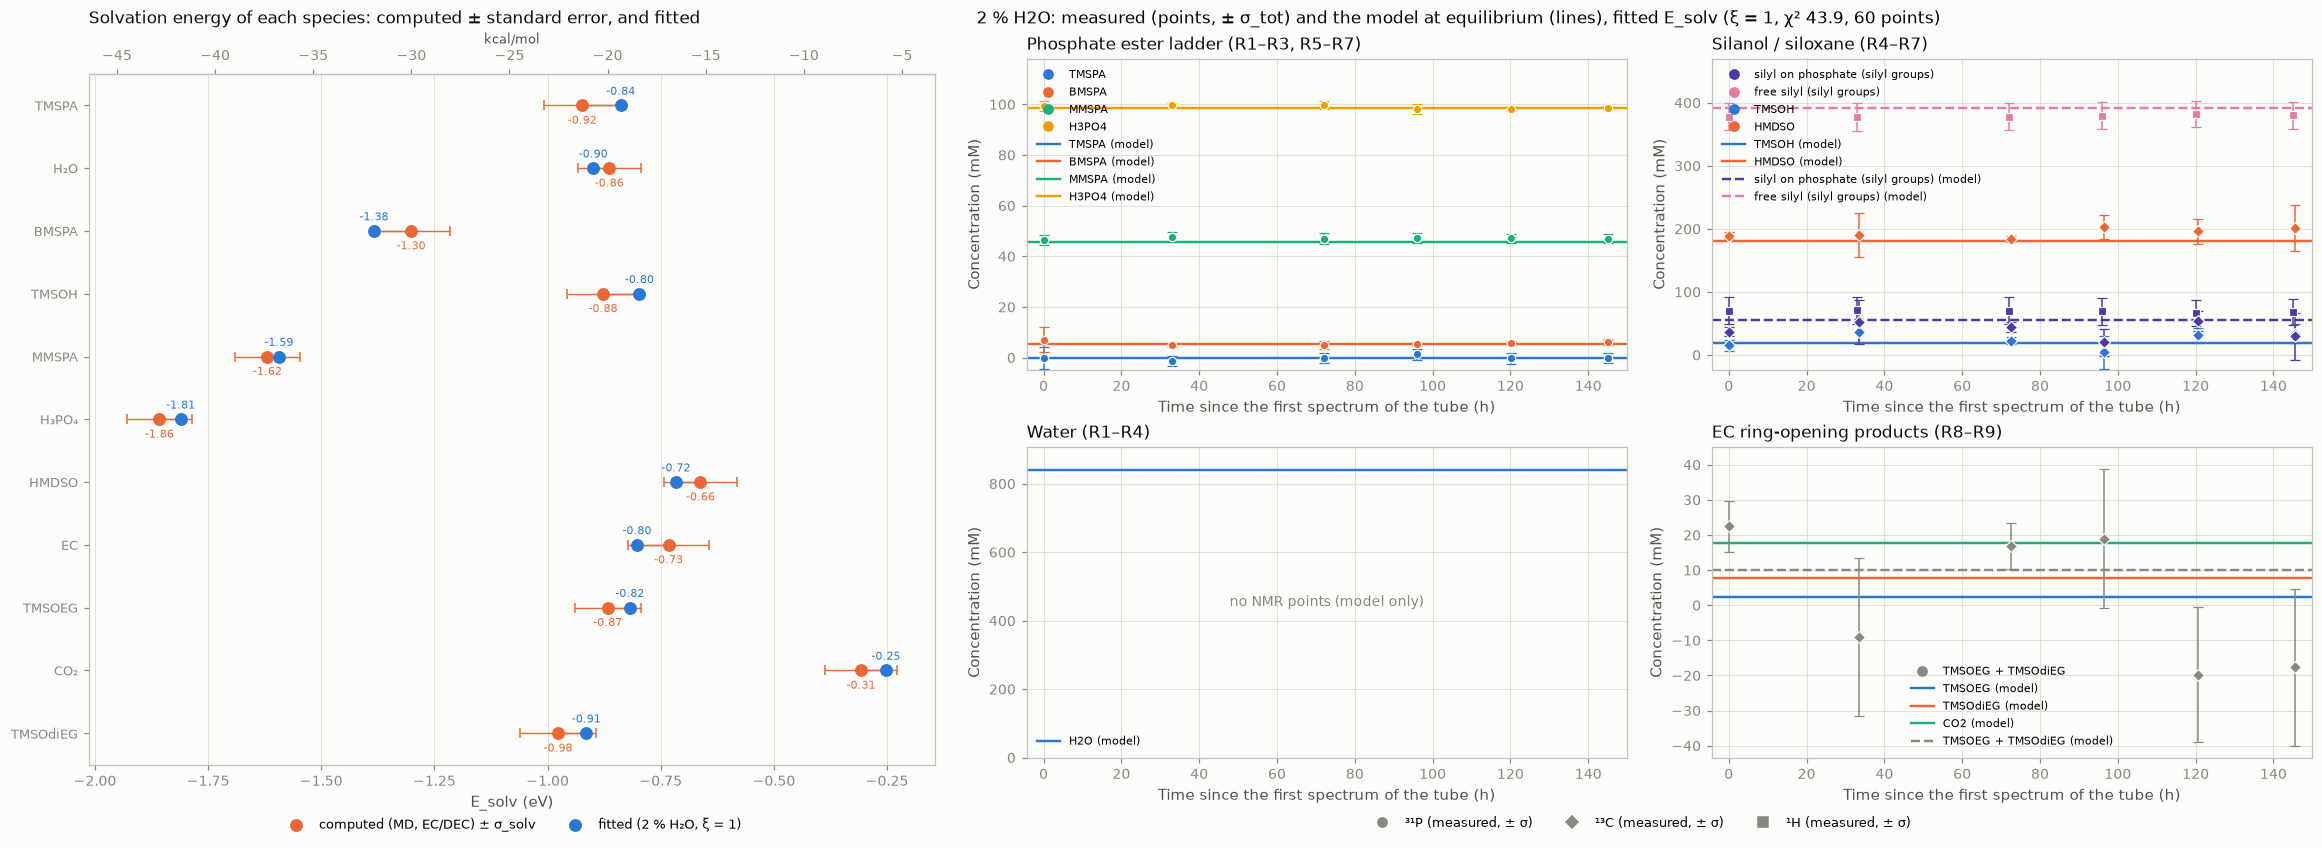

In [22]:
# §3.1, one figure: E_solv,i (left) and C(t) of the 2 % H2O tube (right), with the fit of 2 % H2O alone
TUBE_FIT = '2 % H2O'
sample = build_tube(THERMO_RESULTS, thermo_setup, TUBE_FIT)
C_eq, window_model, chi2, n_points = predict_tube(sample, thermo_setup, fit, XI_SHOWN)
whole = plt.figure(figsize=(21, 7.6), layout='constrained')
left, right = whole.subfigures(1, 2, width_ratios=[1, 1.45])
draw_solvation(left.subplots(), solv, f'fitted (2 % H₂O, ξ = {XI_SHOWN:g})')
draw_fit_concentrations(sample, C_eq, window_model, f"{TUBE_FIT}: measured (points, ± σ_tot) and the model at equilibrium (lines), "
                        f"fitted E_solv (ξ = {XI_SHOWN:g}, χ² {chi2:.1f}, {n_points} points)", fig=right)
display(whole)
plt.close(whole)

## 3.2 2% and 0.5% water fitted

The `0.5 % H2O` tube (N. Gogoi, 2023) has one spectrum per nucleus, 18.9 h after its first one, so the equilibrium rule cannot place it: its quantitative ³¹P (`31P-1-1`) and its ¹³C are declared at equilibrium in the setup of the new run (`notebooks/results/thermo3_2pct_0p5pct`). The ³¹P with d1 1 s (`31Pcpd`) is not quantitative; ²⁹Si is left out, as for 2 %.

### 3.2.1 The fit of §3.1 on the 0.5 % tube

The energies fitted to 2 % H₂O alone (§3.1), not fitted again: how far the model at equilibrium is from the 0.5 % spectra.

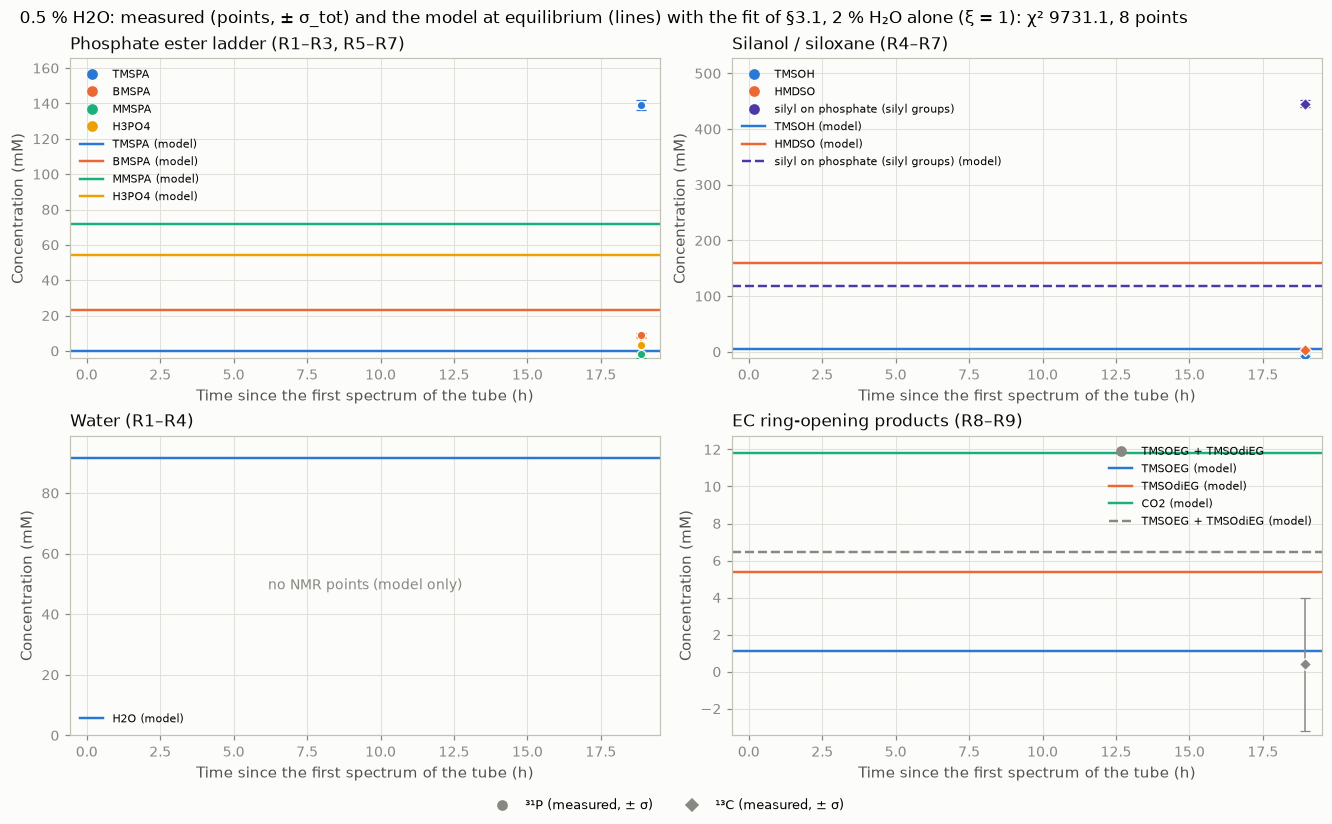

In [23]:
# §3.2.1: C(t) of 0.5 % H2O with the fit of §3.1 (2 % alone). Its spectra as the run of §3.2 reads them (the overrides)
BOTH_RESULTS = REPO / 'notebooks' / 'results' / 'thermo3_2pct_0p5pct'
TUBE_HALF = '0.5 % H2O'
half = build_tube(BOTH_RESULTS, load_thermo_setup(apply_fit_config(BOTH_RESULTS)), TUBE_HALF)
C_eq, window_model, chi2, n_points = predict_tube(half, thermo_setup, fit, XI_SHOWN)
fig = draw_fit_concentrations(half, C_eq, window_model, f"{TUBE_HALF}: measured (points, ± σ_tot) and the model at equilibrium "
                              f"(lines) with the fit of §3.1, 2 % H₂O alone (ξ = {XI_SHOWN:g}): χ² {chi2:.1f}, {n_points} points")
display(fig)
plt.close(fig)

### 3.2.2 Fit of both tubes

One fit, the objective and the model of §2, over the spectra of `2 % H2O` (60 points) and `0.5 % H2O` (8 points) together. It does not replace the fit of §3.1: the two runs coexist (`thermo2_2pctH2O`, `thermo3_2pct_0p5pct`).

xi,tube,chi2,points,max |z|,worst
1,0.5 % H2O,6469.5,8,48.2,13C P-silyl
1,2 % H2O,1002.1,60,16.4,13C TMSOH
2,0.5 % H2O,3226.2,8,36.5,13C P-silyl
2,2 % H2O,1234.2,60,9.6,31P TMSPA
3,0.5 % H2O,3227.2,8,36.5,13C P-silyl
3,2 % H2O,1233.2,60,9.6,31P TMSPA


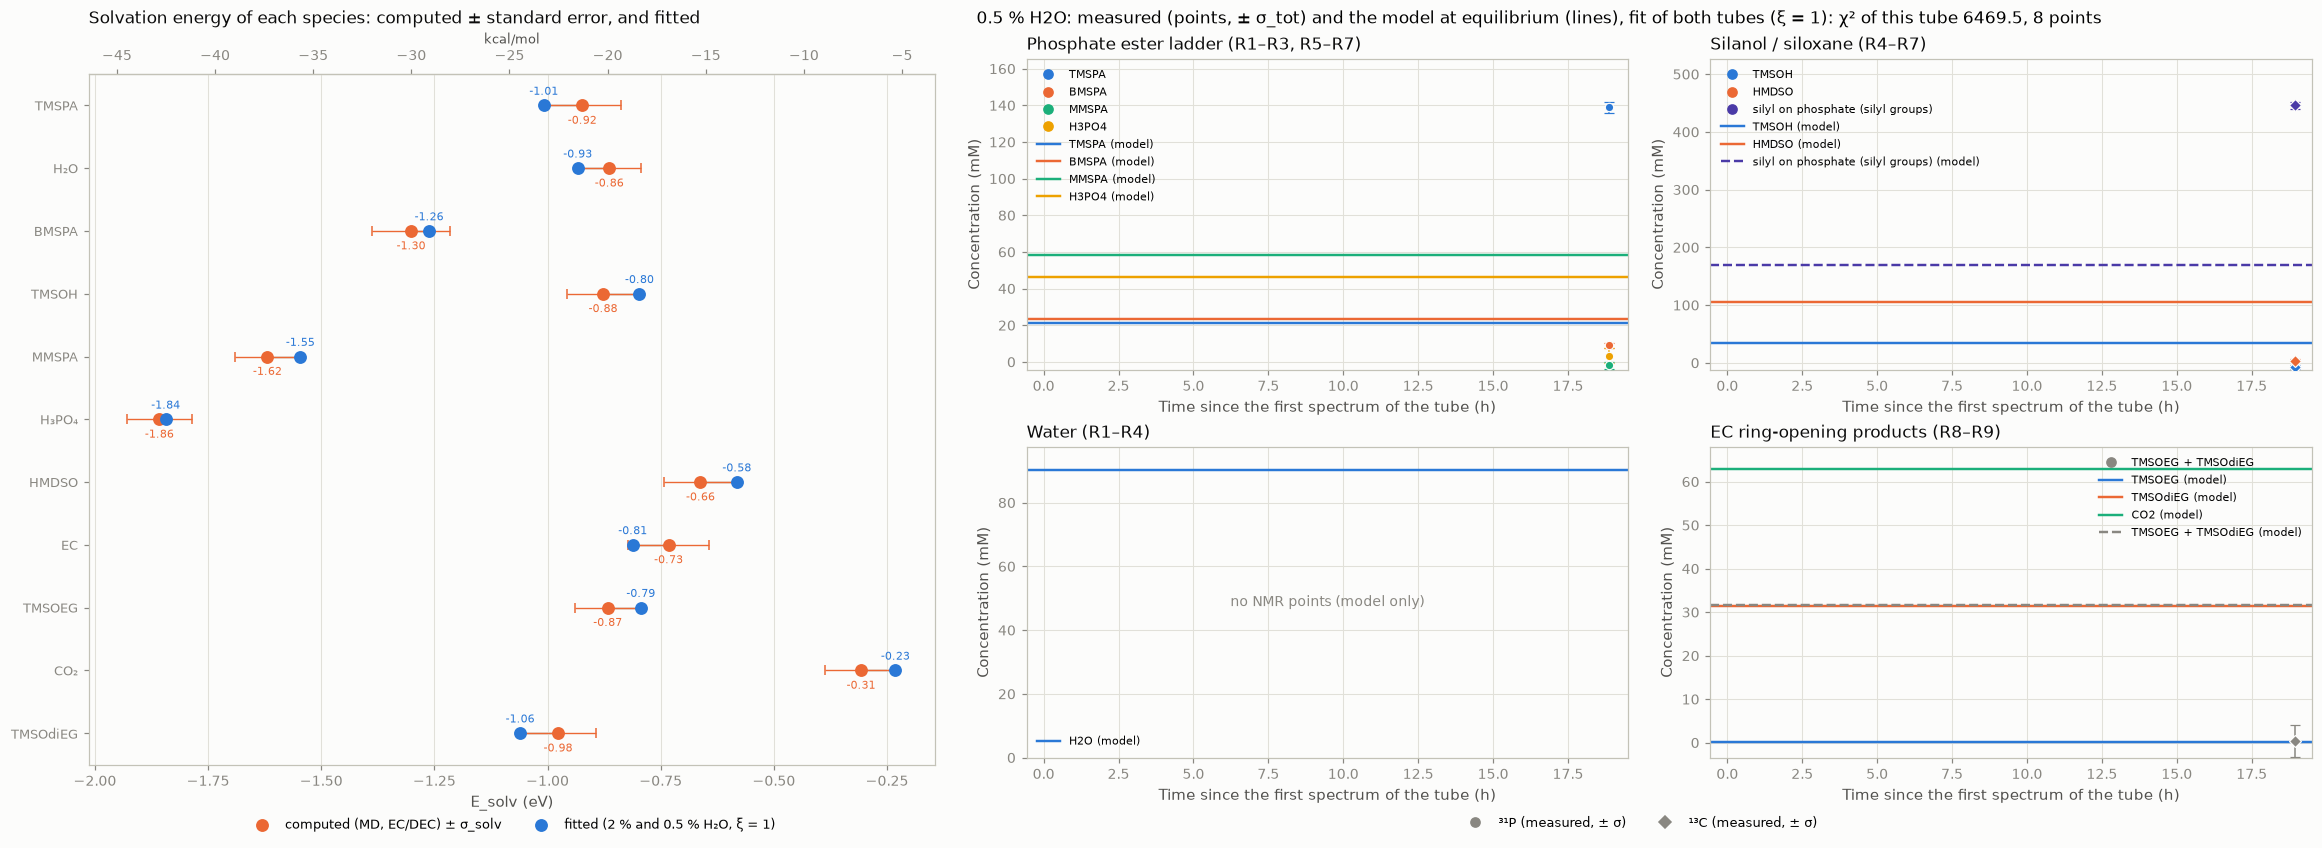

In [24]:
# §3.2.2: the run of both tubes. χ² of each tube under its fit (every ξ), then one figure: E_solv,i (left) and C(t) of
# 0.5 % H2O (right)
BOTH_CONFIG, both_setup, fit_both = load_thermo_run(BOTH_RESULTS, XI_SHOWN)
scores = pd.read_csv(BOTH_RESULTS / 'steps_scores.csv').query("nuclei == 'fit' and role == 'fitted here'")
display(scores[['xi', 'tube', 'chi2', 'n_residuals', 'max |z|', 'worst']].rename(columns={'n_residuals': 'points'})
        .style.hide(axis='index').format({'xi': '{:g}', 'chi2': '{:.1f}', 'max |z|': '{:.1f}'})
        .set_caption('Fit of 2 % and 0.5 % H₂O: χ² of each tube'))
solv_both = tabulate_solvation(fit_both)
C_eq, window_model, chi2, n_points = predict_tube(half, both_setup, fit_both, XI_SHOWN)
whole = plt.figure(figsize=(21, 7.6), layout='constrained')
left, right = whole.subfigures(1, 2, width_ratios=[1, 1.45])
draw_solvation(left.subplots(), solv_both, f'fitted (2 % and 0.5 % H₂O, ξ = {XI_SHOWN:g})')
draw_fit_concentrations(half, C_eq, window_model, f"{TUBE_HALF}: measured (points, ± σ_tot) and the model at equilibrium (lines), "
                        f"fit of both tubes (ξ = {XI_SHOWN:g}): χ² of this tube {chi2:.1f}, {n_points} points", fig=right)
display(whole)
plt.close(whole)

# 4. Fitting Kinetics

M1 fitted to the `2 % H2O` tube of 05/11/2026 (§2) alone. No other tube enters the fit.

- **Data:** the five ³¹P spectra, 5–24 min after the water (20 shares). ¹H not used (Si–CH₃ region is noise, §2.2.2); no ¹³C recorded.
- **Times:** known. t = 0 is the water added to the TMSPa (16:33:04, §2); a spectrum is at the start of its acquisition. No age is guessed.
- **At t = 0:** the recipe, TMSPA 149 mM and H₂O 1 052 mM in EC/DEC 1:1, at the temperature of the spectra (22.3 °C).
- **E_solv,i:** those of the thermo fit of §3.1 (`thermo2_2pctH2O`, ξ = 1). They set ΔG of every reaction, so where the reactions stop (the equilibrium); the barriers set only how fast the tube gets there.
- **Model:** M1, one barrier per family (hydrolysis, transfer, condensation, solvent attack), all four free within their boxes; network R1–R9 + N10–N15.
- **Error of a share:** each spectrum on its own (noise ⊕ baseline ⊕ declared floor): the tube reacts while recorded, so its spectra are not repeats of one composition.
- **Run:** `notebooks/results/kin_M1_2pct-261105_Esolv-thermo2`. For comparison, the same fit with the computed E_solv,i: `kin_M1_2pct-261105`.

In [ ]:
# §4: the fit with the E_solv,i of the thermo fit (kin_M1_2pct-261105_Esolv-thermo2, step K1), beside the same fit with the
# computed E_solv,i (kin_M1_2pct-261105). Each barrier: fitted value and its 95 % range from the profile (χ² within 3.84 of the
# best); '≤' where the range reaches the bottom of the box (any faster is as good), 'not determined' where the ³¹P does not fix it
from kinetics.data import load_lab_observables
from kinetics.fitting.candidates import BARRIER_BOX_EV
from kinetics.fitting.reporting import evaluate_fit, simulate_fit_trajectories, tabulate_fit_shares

KIN_RUNS = {'E_solv thermo fit': REPO / 'notebooks' / 'results' / 'kin_M1_2pct-261105_Esolv-thermo2',
            'E_solv computed': REPO / 'notebooks' / 'results' / 'kin_M1_2pct-261105'}
KIN_RESULTS = KIN_RUNS['E_solv thermo fit']
KIN_TUBE = '2 % H2O, 05/11/2026'
kin_fits = {label: load_fit_result(str(path / 'steps' / 'M1__K1__10_min.json')) for label, path in KIN_RUNS.items()}
kin_fit = kin_fits['E_solv thermo fit']
kin_observables = load_lab_observables(str(KIN_RESULTS / 'data_dir' / 'data' / 'lab_observables.json'))


def kin_range(row, name):
    if row['status'] != 'interval':
        return 'not determined'
    at_bottom = row['low'] - BARRIER_BOX_EV[name.removeprefix('g ')][0] < 0.01
    return f"≤ {row['high']:.3f}" if at_bottom else f"{row['low']:.3f} – {row['high']:.3f}"


table = {}
for label, path in KIN_RUNS.items():
    intervals = pd.read_csv(path / 'steps_intervals.csv').set_index('parameter')
    fit_k = kin_fits[label]
    for name, g in fit_k['theta'].items():
        barrier = name.removeprefix('g ').replace('_', ' ')
        table.setdefault(barrier, {})[(label, 'fitted (eV)')] = f'{g:.3f}' + (' (box edge)' if name in fit_k['at_bounds'] else '')
        table[barrier][(label, '95 % range (eV)')] = kin_range(intervals.loc[name], name)
    table.setdefault('χ² (20 shares)', {})[(label, 'fitted (eV)')] = f"{fit_k['chi2']:.1f}"
    table.setdefault('max |z|', {})[(label, 'fitted (eV)')] = f"{fit_k['max_abs_z']:.1f}"
display(pd.DataFrame(table).T.fillna('').style.set_caption(f'M1 on {KIN_TUBE} alone: the barriers under each set of E_solv,i'))

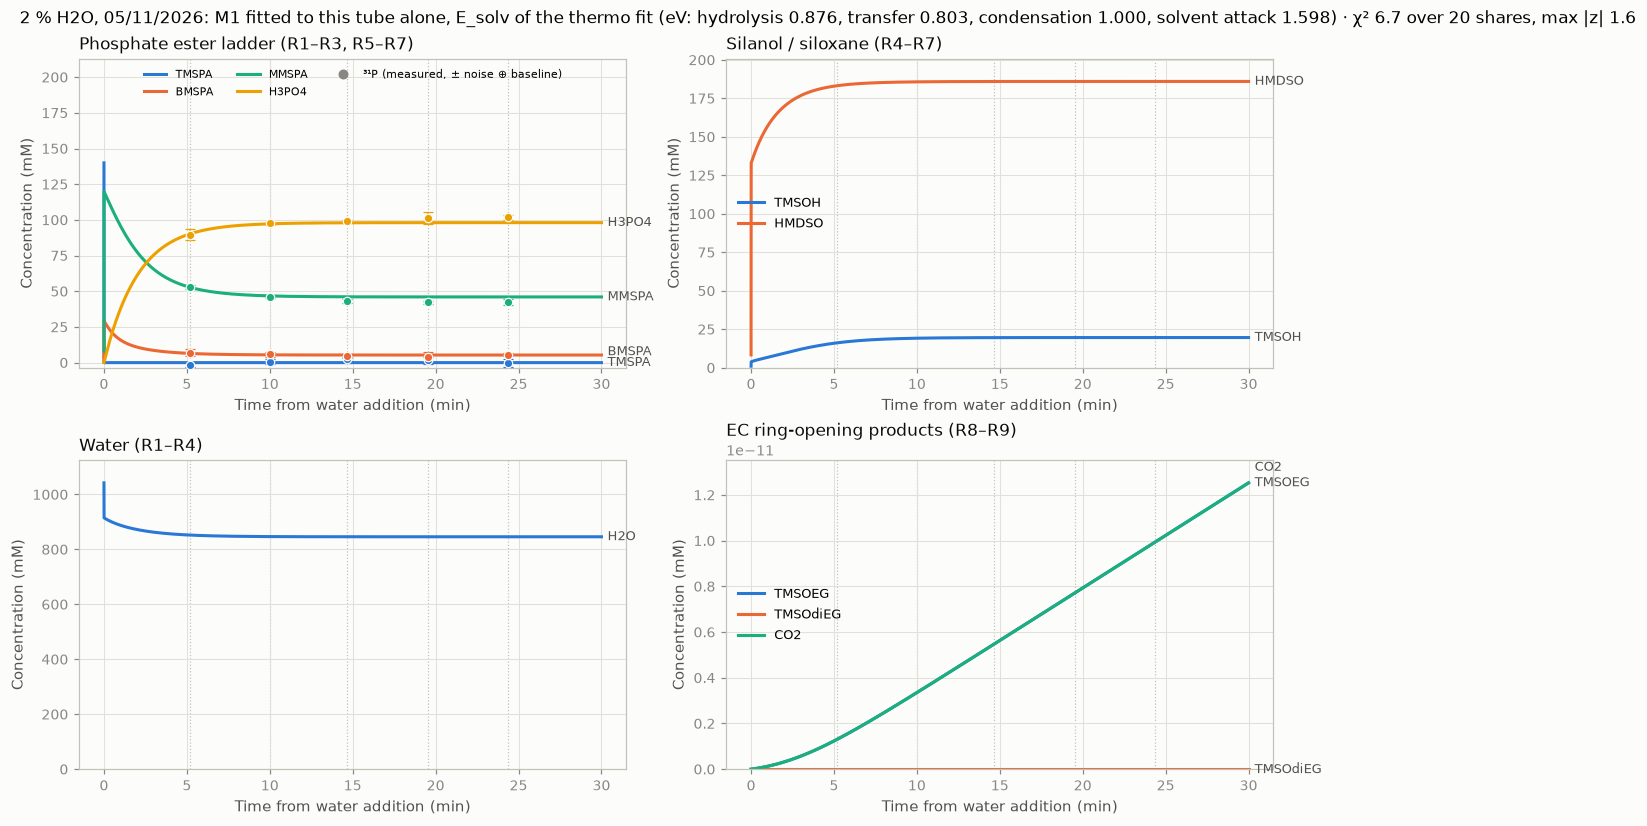

In [ ]:
# §4: C(t) of the tube under the fit with the E_solv,i of the thermo fit. Lines: the fitted M1 from the water (t = 0); points:
# ³¹P, share × total P (149 mM), ± noise ⊕ baseline
from demo.reactor_plots import CONCENTRATION_PANELS, plot_concentration_panels
from kinetics.constants import ZERO_CELSIUS_K
from matplotlib.lines import Line2D

KIN_UNTIL_H = 0.5                                         # the model drawn to 30 min after the water
try:
    apply_fit_config(KIN_RESULTS)                         # its solvent (EC/DEC), network and E_solv,i of the thermo fit
    evaluation = evaluate_fit(kin_fit, kin_observables)
    shares = tabulate_fit_shares(evaluation)
    curve = simulate_fit_trajectories(evaluation, until_h=KIN_UNTIL_H, t_first_h=1e-6, n_points=600)   # from 0.004 s: TMSPA reacts within seconds
finally:
    apply_fit_config(THERMO_RESULTS)                      # back to the setup of §3
species = [c for c in curve.columns if c not in ('sample', 't_h', 'T_C')]
sim = {'model': '', 't_h': 60.0 * curve['t_h'].to_numpy(), 'T_K': curve['T_C'].to_numpy() + ZERO_CELSIUS_K,
       'C_mM': 1000.0 * np.clip(curve[species].to_numpy().T, 0.0, None), 'idx': {sp: i for i, sp in enumerate(species)},
       'acquisitions': [{'t_h': 60.0 * t} for t in shares['t_h'].unique()],     # dotted line at each ³¹P
       'time_label': 'Time from water addition (min)'}
fig = plot_concentration_panels(sim, from_zero=True)
ax = fig.axes[0]                                           # the phosphate panel: the ³¹P windows, one species each
for k, sp in enumerate(CONCENTRATION_PANELS[0][1]):
    seen = shares[shares['window'] == sp]
    y, error = 1000.0 * seen['measured'] * seen['total_M'], 1000.0 * seen['sigma_nmr'] * seen['total_M']
    ax.errorbar(60.0 * seen['t_h'], y, yerr=error, fmt='o', color=style.SERIES[k], markersize=5.5,
                markeredgecolor=fit_plots.SURFACE, markeredgewidth=0.8, elinewidth=1.0, capsize=3, zorder=4)
    low, high = ax.get_ylim()
    ax.set_ylim(min(low, 1.08 * float((y - error).min())), max(high, 1.08 * float((y + error).max())))
handles, _ = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color=fit_plots.INK_MUTED, marker='o', linestyle='none', markersize=5.5,
                      label='³¹P (measured, ± noise ⊕ baseline)'))
low, high = ax.get_ylim()
ax.set_ylim(low, low + 1.4 * (high - low))                 # room above the data for the legend
ax.legend(handles=handles, loc='upper center', ncols=3, fontsize=7.5)
theta = ', '.join(f"{name.removeprefix('g ').replace('_', ' ')} {g:.3f}" for name, g in kin_fit['theta'].items())
fig.suptitle(f"{KIN_TUBE}: M1 fitted to this tube alone, E_solv of the thermo fit (eV: {theta}) · χ² {kin_fit['chi2']:.1f} over "
             f"{kin_fit['n_residuals']} shares, max |z| {kin_fit['max_abs_z']:.1f}", x=0.01, ha='left', fontsize=11)
display(fig)
plt.close(fig)

# 5. Solvent simulations

## 5.1 Pure DEC

M1 at room temperature in neat DEC:

- **g:** fitted, last step of the M1-steps run (`fit8_M1-steps_S1-tube`, S5, 1 h reading).
- **E_solv,i:** MD solvation in neat DEC (2026-10-08 snapshot).
- **At t = 0:** TMSPA and water of the `0.5 % H2O` and `2 % H2O` recipes, no EC.

Solvent: neat DEC, MD solvation of the 2026-10-08 snapshot
g of M1 S5 (1 h): hydrolysis 1.102 eV, transfer 0.943 eV, condensation 1.129 eV, solvent attack 1.222 eV


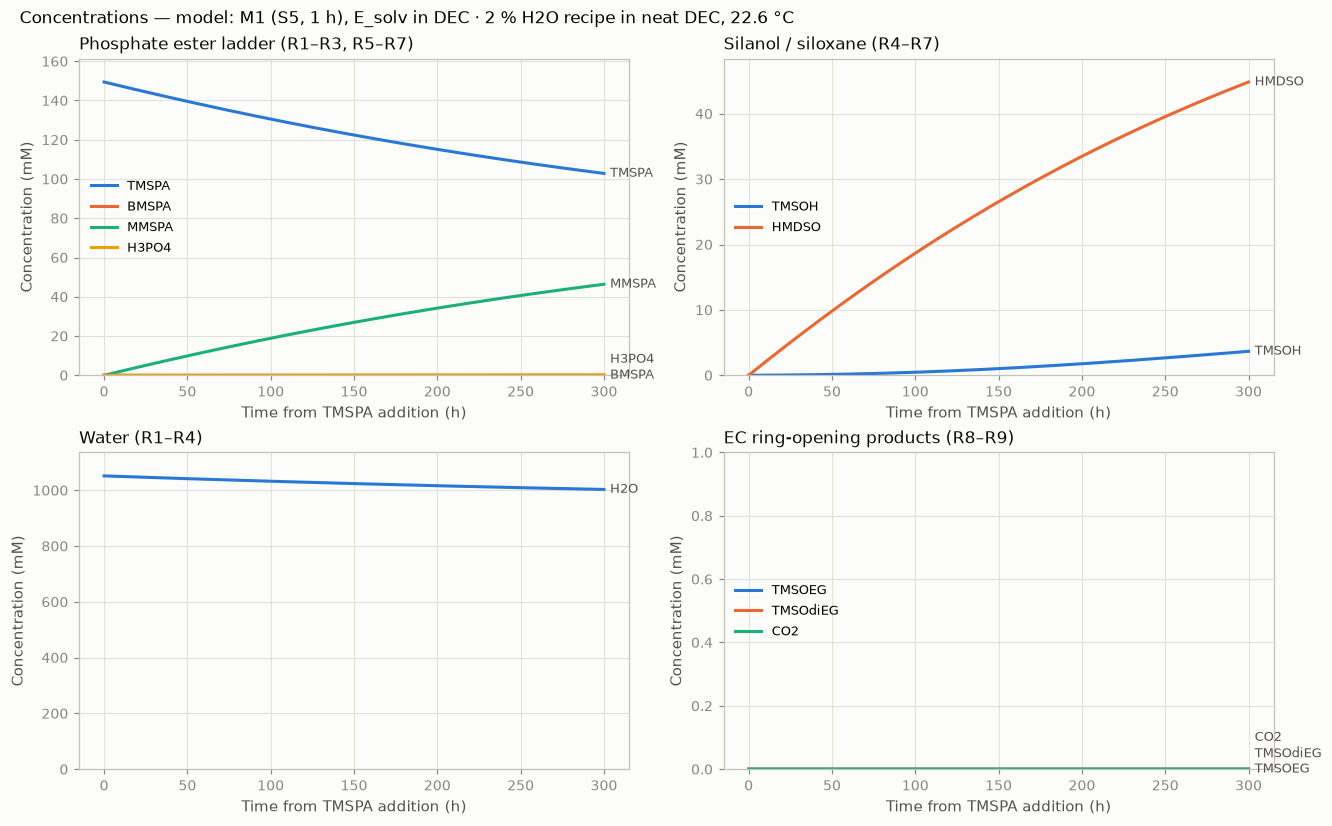

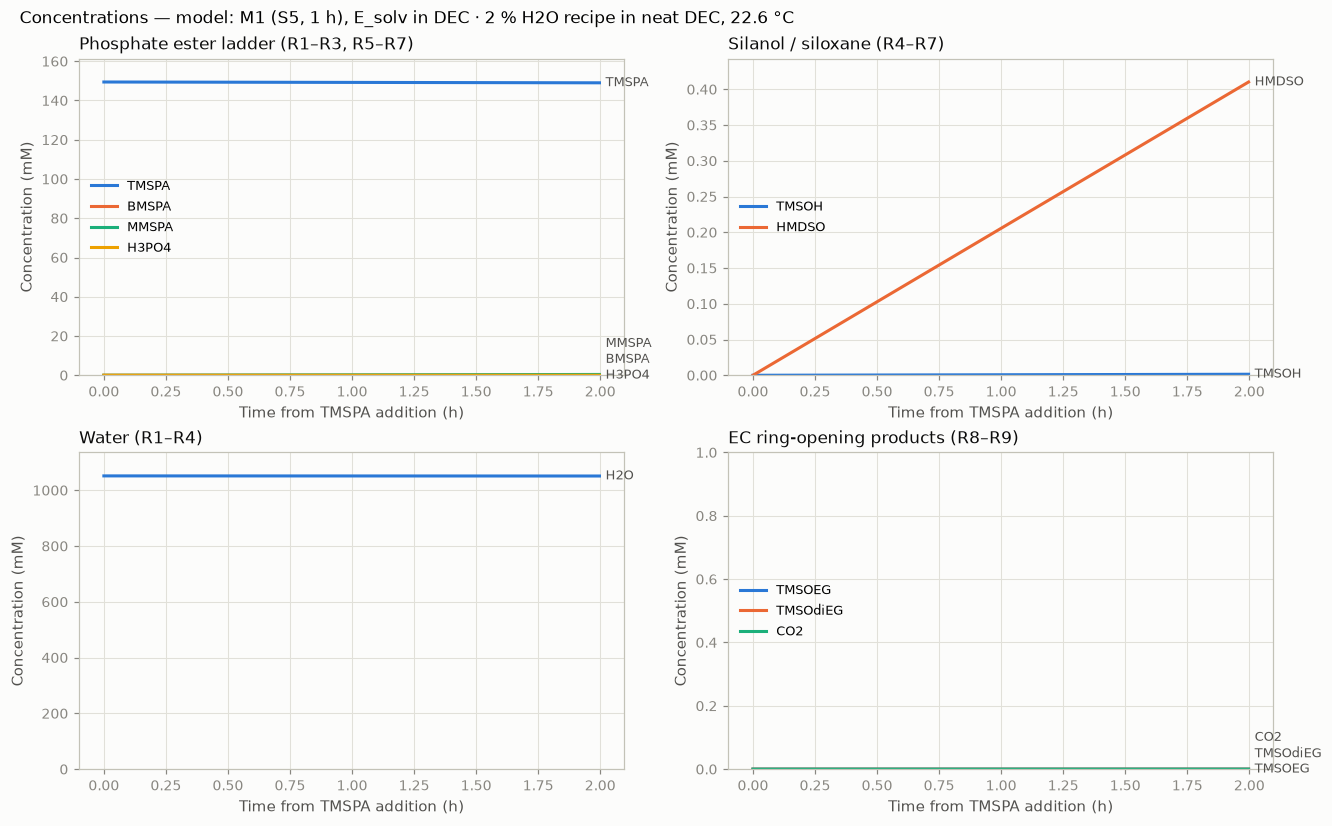

In [35]:
# §5.1: M1 in neat DEC at room temperature. g of each family: the last step of the M1-steps run (S5, 1 h reading).
# E_solv,i: MD solvation in neat DEC (2026-10-08 snapshot). Composition at mixing: the recipe of each tube without EC
import numpy as np
from demo.reactor_plots import plot_concentration_panels
from kinetics.constants import ZERO_CELSIUS_K
from kinetics.data.medium import SolvationMedium, set_active_medium
from kinetics.fitting import get_structure
from kinetics.reactor import simulate_history

M1_RESULTS = REPO / 'notebooks' / 'results' / 'fit8_M1-steps_S1-tube'
M1_STEP, M1_READING = 'S5', '1 h'
SOLVENT_TUBES = ['2 % H2O']
ZOOM_H = 2.0                                              # second plot: only the first 2 h
SIM_H = 300.0                                             # hours simulated from TMSPA addition

m1_config = apply_fit_config(M1_RESULTS)                  # its network
m1_fit = load_fit_result(str(M1_RESULTS / 'steps' / f"M1__{M1_STEP}__{M1_READING.replace(' ', '_')}.json"))
DEC_MEDIUM = SolvationMedium(snapshot=m1_config['medium'].snapshot, volume_fractions=(('DEC', 1.0),))
times_s = np.r_[0.0, np.geomspace(1.0, 3600.0 * SIM_H, 3000)]
dec_runs = {}
try:
    set_active_medium(DEC_MEDIUM)
    m1_model = get_structure(m1_fit['structure']).build(m1_fit['theta'])['model']
    for tube in SOLVENT_TUBES:
        record = observables['samples'][tube]
        c0 = {sp: c for sp, c in record['c0_M'].items() if sp != 'EC'}
        T_K = record['T_rt_C'] + ZERO_CELSIUS_K
        dec_runs[tube] = (simulate_history(c0, [(T_K, 3600.0 * SIM_H)], times_s, model=m1_model), T_K)
finally:
    apply_fit_config(THERMO_RESULTS)                      # back to the setup of §3
print(f"Solvent: {DEC_MEDIUM.label()}")
print(f"g of M1 {M1_STEP} ({M1_READING}): " + ', '.join(f"{name.removeprefix('g ').replace('_', ' ')} {g:.3f} eV"
                                                       for name, g in m1_fit['theta'].items()))
for tube, (run, T_K) in dec_runs.items():
    sim = {'model': f"M1 ({M1_STEP}, {M1_READING}), E_solv in DEC · {tube} recipe in neat DEC, {T_K - ZERO_CELSIUS_K:.1f} °C",
           't_h': times_s / 3600.0, 'T_K': np.full(times_s.size, T_K), 'C_mM': 1000.0 * np.clip(run['C_M'], 0.0, None),
           'idx': run['idx'], 'acquisitions': [], 'time_label': 'Time from TMSPA addition (h)'}
    keep = sim['t_h'] <= ZOOM_H
    zoom = {**sim, 't_h': sim['t_h'][keep], 'T_K': sim['T_K'][keep], 'C_mM': sim['C_mM'][:, keep]}
    for s_ in (sim, zoom):
        fig = plot_concentration_panels(s_, from_zero=True)
        display(fig)
        plt.close(fig)